In [2]:
from pathlib import Path
import kagglehub

# Match the dataset version shown in the group's data_load notebook.
dataset_path = Path(
    kagglehub.dataset_download("liugalhigh/beach-bird/versions/3")
)

DATASET_DIR = dataset_path / "Beach Bird Detection Dataset v1.0"

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(
        f"Expected dataset folder not found: {DATASET_DIR}\n"
        f"Downloaded folder contains: {[p.name for p in dataset_path.iterdir()]}"
    )

print("Dataset location:", DATASET_DIR)

Dataset location: C:\Users\raksh\.cache\kagglehub\datasets\liugalhigh\beach-bird\versions\3\Beach Bird Detection Dataset v1.0


In [3]:
# Cell 3: Find and inspect dataset configuration files

yaml_files = sorted(
    list(DATASET_DIR.rglob("*.yaml")) +
    list(DATASET_DIR.rglob("*.yml"))
)

if yaml_files:
    for path in yaml_files:
        print(f"\n--- {path.relative_to(DATASET_DIR)} ---")
        print(path.read_text(encoding="utf-8"))
else:
    print("No YAML configuration found. We will create one after checking the folders.")


--- dataset.yaml ---
path: .
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: bird



In [4]:
import numpy as np
import pandas as pd
from IPython.display import display

# Use the folder containing dataset.yaml as the dataset root.
config_files = list(DATASET_DIR.rglob("dataset.yaml"))

if len(config_files) != 1:
    raise ValueError(
        f"Expected one dataset.yaml, found {len(config_files)}: {config_files}"
    )

DATA_ROOT = config_files[0].parent

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
split_images = {}
issues = []
summary = []


def read_boxes(label_path):
    text = label_path.read_text(encoding="utf-8").strip()

    # An empty label file represents an image with no annotated birds.
    if not text:
        return np.empty((0, 5), dtype=float)

    boxes = np.array(
        [list(map(float, line.split())) for line in text.splitlines()],
        dtype=float
    )

    if boxes.ndim != 2 or boxes.shape[1] != 5:
        raise ValueError("Each row must contain exactly five numbers.")

    if not np.isfinite(boxes).all():
        raise ValueError("Label contains NaN or infinite values.")

    if not (boxes[:, 0] == 0).all():
        raise ValueError("Expected class ID 0 for bird.")

    centres = boxes[:, 1:3]
    sizes = boxes[:, 3:5]

    if ((centres < 0) | (centres > 1)).any():
        raise ValueError("Box centres must be between 0 and 1.")

    if ((sizes <= 0) | (sizes > 1)).any():
        raise ValueError("Box widths and heights must be greater than 0 and at most 1.")

    # Allow a small tolerance for rounding in annotation files.
    if ((centres - sizes / 2 < -0.001) |
        (centres + sizes / 2 > 1.001)).any():
        raise ValueError("A bounding box extends outside the image.")

    return boxes


# Inspect development data; leave test evaluation until the final stage.
for split in ["train", "val"]:
    image_dir = DATA_ROOT / "images" / split
    label_dir = DATA_ROOT / "labels" / split

    if not image_dir.is_dir() or not label_dir.is_dir():
        raise FileNotFoundError(
            f"Missing image or label folder for {split}:\n"
            f"{image_dir}\n{label_dir}"
        )

    images = sorted(
        p for p in image_dir.rglob("*")
        if p.suffix.lower() in IMAGE_EXTENSIONS
    )

    if not images:
        raise ValueError(f"No images found in {image_dir}")

    split_images[split] = images
    bird_count = 0
    empty_count = 0
    missing_count = 0
    invalid_count = 0

    for image_path in images:
        relative_path = image_path.relative_to(image_dir)
        label_path = label_dir / relative_path.with_suffix(".txt")

        if not label_path.exists():
            missing_count += 1
            issues.append((split, image_path.name, "Missing label file"))
            continue

        try:
            boxes = read_boxes(label_path)
            bird_count += len(boxes)
            empty_count += int(len(boxes) == 0)
        except ValueError as error:
            invalid_count += 1
            issues.append((split, image_path.name, str(error)))

    summary.append({
        "Split": split,
        "Images": len(images),
        "Birds in valid labels": bird_count,
        "Empty labels": empty_count,
        "Missing labels": missing_count,
        "Invalid labels": invalid_count
    })

display(pd.DataFrame(summary))

if issues:
    display(pd.DataFrame(
        issues, columns=["Split", "Image", "Issue"]
    ).head(20))
    print(f"Found {len(issues)} issues. Check these before training.")
else:
    print("All training and validation label files passed.")

,Split,Images,Birds in valid labels,Empty labels,Missing labels,Invalid labels
0,train,1369,8663,154,0,0
1,val,291,1843,33,0,0


All training and validation label files passed.


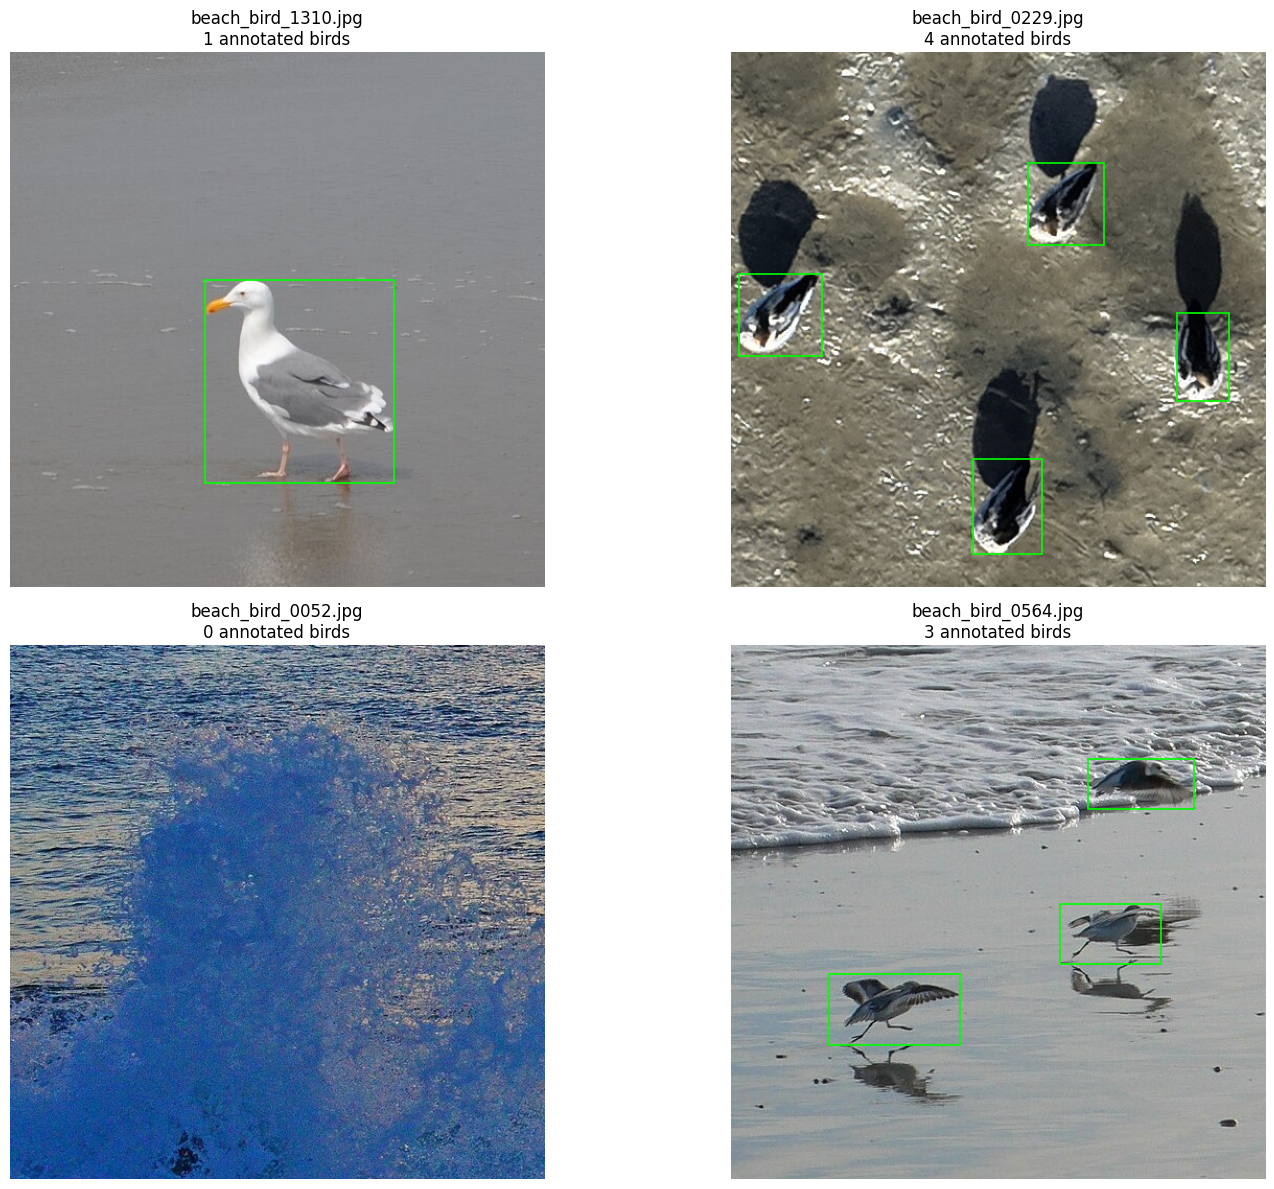

In [5]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

sample_images = random.Random(42).sample(
    split_images["train"],
    k=min(4, len(split_images["train"]))
)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, image_path in zip(axes.flat, sample_images):
    relative_path = image_path.relative_to(DATA_ROOT / "images" / "train")
    label_path = (
        DATA_ROOT / "labels" / "train" / relative_path.with_suffix(".txt")
    )

    with Image.open(image_path) as source:
        image = source.convert("RGB")

    width, height = image.size
    ax.imshow(image)

    if label_path.exists():
        boxes = read_boxes(label_path)

        for _, centre_x, centre_y, box_width, box_height in boxes:
            x = (centre_x - box_width / 2) * width
            y = (centre_y - box_height / 2) * height

            ax.add_patch(Rectangle(
                (x, y),
                box_width * width,
                box_height * height,
                fill=False,
                edgecolor="lime",
                linewidth=1.2
            ))

        ax.set_title(f"{image_path.name}\n{len(boxes)} annotated birds")
    else:
        ax.set_title(f"{image_path.name}\nMissing label file")

    ax.axis("off")

for ax in list(axes.flat)[len(sample_images):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
from pathlib import Path
import yaml

YOLO_DIR = Path.cwd() / "yolo_work"
YOLO_DIR.mkdir(parents=True, exist_ok=True)

DATA_YAML = YOLO_DIR / "bird_dataset.yaml"

dataset_config = {
    "path": str(DATA_ROOT.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 1,
    "names": {0: "bird"}
}

with DATA_YAML.open("w", encoding="utf-8") as file:
    yaml.safe_dump(dataset_config, file, sort_keys=False)

print(DATA_YAML.read_text())

path: C:\Users\raksh\.cache\kagglehub\datasets\liugalhigh\beach-bird\versions\3\Beach
  Bird Detection Dataset v1.0
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: bird



In [10]:
import ultralytics

TRAIN_SETTINGS = {
    "data": str(DATA_YAML.resolve()),
    "epochs": 10,
    "imgsz": 640,
    "batch": 8,
    "workers": 0,       # Suitable for Jupyter on Windows
    "seed": 42,
    "deterministic": True,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "patience": 0,      # Disable early stopping: same epoch budget
    "max_det": 300,     # Allow detections in crowded bird images
    "cache": False,
    "project": str((YOLO_DIR / "runs").resolve()),
    "save": True,
    "plots": True
}

# Explicitly disable standard random detection augmentations.
BASELINE_AUGMENTATION = {
    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.0,
    "degrees": 0.0,
    "translate": 0.0,
    "scale": 0.0,
    "shear": 0.0,
    "perspective": 0.0,
    "flipud": 0.0,
    "fliplr": 0.0,
    "mosaic": 0.0,
    "mixup": 0.0,
    "copy_paste": 0.0,
    "close_mosaic": 0,
    "multi_scale": False
}

print("Ultralytics version:", ultralytics.__version__)
print("Training settings:")
display(TRAIN_SETTINGS)

Ultralytics version: 8.4.208
Training settings:


{'data': 'C:\\Users\\raksh\\Desktop\\CompVis\\yolo_work\\bird_dataset.yaml',
 'epochs': 10,
 'imgsz': 640,
 'batch': 8,
 'workers': 0,
 'seed': 42,
 'deterministic': True,
 'optimizer': 'AdamW',
 'lr0': 0.001,
 'patience': 0,
 'max_det': 300,
 'cache': False,
 'project': 'C:\\Users\\raksh\\Desktop\\CompVis\\yolo_work\\runs',
 'save': True,
 'plots': True}

In [11]:
from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionTrainer


class BaselineTrainer(DetectionTrainer):
    """Train with resizing/padding and formatting, without random augmentation."""

    def build_dataset(self, img_path, mode="train", batch=None):
        dataset = super().build_dataset(
            img_path,
            mode=mode,
            batch=batch
        )

        if mode == "train":
            dataset.augment = False
            dataset.transforms = dataset.build_transforms(hyp=self.args)

            print("\nBaseline training transforms:")
            print(dataset.transforms)

        return dataset

In [12]:
import json
import time
from datetime import datetime

# Stop if the earlier annotation checks found problems.
if issues:
    raise ValueError(
        "Resolve the annotation issues from Cell 4 before training."
    )

# A unique name prevents accidentally overwriting an earlier experiment.
RUN_NAME = "baseline_seed42_" + datetime.now().strftime("%Y%m%d_%H%M%S")

# Always begin an experiment from the original pretrained weights.
baseline_model = YOLO("yolo11n.pt")

start_time = time.perf_counter()

baseline_results = baseline_model.train(
    trainer=BaselineTrainer,
    **TRAIN_SETTINGS,
    **BASELINE_AUGMENTATION,
    name=RUN_NAME,
    exist_ok=False
)

training_seconds = time.perf_counter() - start_time

BASELINE_RUN_DIR = Path(baseline_model.trainer.save_dir)
BASELINE_WEIGHTS = BASELINE_RUN_DIR / "weights" / "best.pt"

run_summary = {
    "experiment": "baseline_no_random_augmentation",
    "model": "yolo11n",
    "initial_weights": "yolo11n.pt",
    "ultralytics_version": ultralytics.__version__,
    "seed": TRAIN_SETTINGS["seed"],
    "wall_time_seconds": training_seconds,
    "wall_time_minutes": training_seconds / 60,
    "best_weights": str(BASELINE_WEIGHTS.resolve()),
    "note": "Wall time includes training setup and validation."
}

with (BASELINE_RUN_DIR / "run_summary.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(run_summary, file, indent=2)

print(f"\nRun duration: {training_seconds / 60:.2f} minutes")
print("Results folder:", BASELINE_RUN_DIR)
print("Best model:", BASELINE_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.210 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.208  Python-3.13.12 torch-2.15.0+cpu CPU (Intel Core Ultra 5 125H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\raksh\Desktop\CompVis\yolo_work\bird_dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, m

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

BASELINE_RUN_DIR = Path(
    r"C:\Users\raksh\Desktop\CompVis\yolo_work\runs"
    r"\baseline_seed42_20261111_140300"
)

BASELINE_WEIGHTS = BASELINE_RUN_DIR / "weights" / "best.pt"

if not BASELINE_WEIGHTS.is_file():
    raise FileNotFoundError(BASELINE_WEIGHTS)

history = pd.read_csv(BASELINE_RUN_DIR / "results.csv")
history.columns = history.columns.str.strip()

# Both mAP metrics peak at epoch 9 in this run.
best_row = history.loc[history["metrics/mAP50-95(B)"].idxmax()]

baseline_summary = pd.DataFrame([{
    "Model": "YOLO11n",
    "Augmentation": "None",
    "Epochs completed": int(history["epoch"].max()),
    "Best CSV epoch": int(best_row["epoch"]),
    "Validation mAP@0.5": best_row["metrics/mAP50(B)"],
    "Validation mAP@0.5–0.95": best_row["metrics/mAP50-95(B)"],
    "Validation precision": best_row["metrics/precision(B)"],
    "Validation recall": best_row["metrics/recall(B)"]
}])

display(baseline_summary.round(4))
print("Saved baseline weights:", BASELINE_WEIGHTS)

,Model,Augmentation,Epochs completed,Best CSV epoch,Validation mAP@0.5,Validation mAP@0.5–0.95,Validation precision,Validation recall
0,YOLO11n,None,10,9,0.8309,0.4271,0.8452,0.7591


Saved baseline weights: C:\Users\raksh\Desktop\CompVis\yolo_work\runs\baseline_seed42_20261111_140300\weights\best.pt


In [2]:
from ultralytics.models.yolo.detect import DetectionTrainer
from ultralytics.data.augment import RandomFlip, Format


class HorizontalFlipTrainer(DetectionTrainer):
    """Baseline preprocessing plus random horizontal flips."""

    def build_dataset(self, img_path, mode="train", batch=None):
        dataset = super().build_dataset(
            img_path,
            mode=mode,
            batch=batch
        )

        if mode == "train":
            # Rebuild the same deterministic pipeline as the baseline.
            dataset.augment = False
            dataset.transforms = dataset.build_transforms(hyp=self.args)

            transforms = dataset.transforms.transforms

            # Insert the flip immediately before tensor formatting.
            format_positions = [
                i for i, transform in enumerate(transforms)
                if isinstance(transform, Format)
            ]

            if len(format_positions) != 1:
                raise RuntimeError(
                    "Unexpected transform pipeline. Stop and inspect it."
                )

            transforms.insert(
                format_positions[0],
                RandomFlip(
                    p=self.args.fliplr,
                    direction="horizontal"
                )
            )

            print("\nHorizontal flip training pipeline:")
            print(dataset.transforms)

        return dataset

In [5]:
from pathlib import Path

YOLO_DIR = Path(r"C:\Users\raksh\Desktop\CompVis\yolo_work")
DATA_YAML = YOLO_DIR / "bird_dataset.yaml"

if not DATA_YAML.is_file():
    raise FileNotFoundError(f"Dataset configuration not found: {DATA_YAML}")

TRAIN_SETTINGS = {
    "data": str(DATA_YAML.resolve()),
    "epochs": 10,
    "imgsz": 640,
    "batch": 8,
    "workers": 0,
    "seed": 42,
    "deterministic": True,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "patience": 0,
    "max_det": 300,
    "cache": False,
    "project": str((YOLO_DIR / "runs").resolve()),
    "save": True,
    "plots": True
}

BASELINE_AUGMENTATION = {
    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.0,
    "degrees": 0.0,
    "translate": 0.0,
    "scale": 0.0,
    "shear": 0.0,
    "perspective": 0.0,
    "flipud": 0.0,
    "fliplr": 0.0,
    "mosaic": 0.0,
    "mixup": 0.0,
    "copy_paste": 0.0,
    "close_mosaic": 0,
    "multi_scale": False
}

print("Settings restored. Epochs:", TRAIN_SETTINGS["epochs"])

Settings restored. Epochs: 10


In [6]:
from pathlib import Path
from ultralytics import YOLO
from datetime import datetime
import ultralytics
import json
import time

# Copy the settings so the baseline configuration stays intact.
flip_settings = TRAIN_SETTINGS.copy()
flip_settings["epochs"] = 10

flip_augmentation = BASELINE_AUGMENTATION.copy()
flip_augmentation["fliplr"] = 0.5

FLIP_RUN_NAME = (
    "horizontal_flip_seed42_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)

flip_model = YOLO("yolo11n.pt")

start_time = time.perf_counter()

flip_results = flip_model.train(
    trainer=HorizontalFlipTrainer,
    **flip_settings,
    **flip_augmentation,
    name=FLIP_RUN_NAME,
    exist_ok=False
)

flip_seconds = time.perf_counter() - start_time

FLIP_RUN_DIR = Path(flip_model.trainer.save_dir)
FLIP_WEIGHTS = FLIP_RUN_DIR / "weights" / "best.pt"

flip_summary = {
    "experiment": "horizontal_flip",
    "model": "yolo11n",
    "initial_weights": "yolo11n.pt",
    "trainer": "HorizontalFlipTrainer",
    "horizontal_flip_probability": 0.5,
    "epochs_requested": 10,
    "seed": flip_settings["seed"],
    "ultralytics_version": ultralytics.__version__,
    "wall_time_seconds": flip_seconds,
    "wall_time_minutes": flip_seconds / 60,
    "best_weights": str(FLIP_WEIGHTS.resolve()),
    "note": "Wall time includes setup and validation, and any pauses."
}

with (FLIP_RUN_DIR / "run_summary.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(flip_summary, file, indent=2)

print(f"\nRun duration: {flip_seconds / 60:.2f} minutes")
print("Results folder:", FLIP_RUN_DIR)
print("Best model:", FLIP_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.210 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.208  Python-3.13.12 torch-2.15.0+cpu CPU (Intel Core Ultra 5 125H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\raksh\Desktop\CompVis\yolo_work\bird_dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, m

In [7]:
import random
import numpy as np

from ultralytics.models.yolo.detect import DetectionTrainer
from ultralytics.data.augment import RandomFlip, Format


class RandomBrightnessContrast:
    """Adjust image appearance without changing box coordinates."""

    def __init__(self, p=0.5, contrast=0.2, brightness=0.1):
        self.p = p
        self.contrast = contrast
        self.brightness = brightness

    def __call__(self, labels):
        if random.random() < self.p:
            image = labels["img"].astype(np.float32)

            alpha = random.uniform(
                1.0 - self.contrast,
                1.0 + self.contrast
            )
            beta = random.uniform(
                -self.brightness,
                self.brightness
            ) * 255.0

            # Contrast around the middle of the pixel range,
            # followed by an additive brightness adjustment.
            image = (image - 127.5) * alpha + 127.5 + beta

            labels["img"] = np.clip(image, 0, 255).astype(np.uint8)

        return labels

    def __repr__(self):
        return (
            f"RandomBrightnessContrast(p={self.p}, "
            f"contrast={self.contrast}, brightness={self.brightness})"
        )


class FlipBrightnessContrastTrainer(DetectionTrainer):
    """Baseline preprocessing + horizontal flips + appearance changes."""

    def build_dataset(self, img_path, mode="train", batch=None):
        dataset = super().build_dataset(
            img_path,
            mode=mode,
            batch=batch
        )

        if mode == "train":
            # Use the same deterministic preprocessing as our baseline.
            dataset.augment = False
            dataset.transforms = dataset.build_transforms(hyp=self.args)

            transforms = dataset.transforms.transforms

            format_positions = [
                i for i, transform in enumerate(transforms)
                if isinstance(transform, Format)
            ]

            if len(format_positions) != 1:
                raise RuntimeError(
                    "Unexpected transform pipeline. Stop and inspect it."
                )

            position = format_positions[0]

            transforms.insert(
                position,
                RandomFlip(
                    p=self.args.fliplr,
                    direction="horizontal"
                )
            )

            transforms.insert(
                position + 1,
                RandomBrightnessContrast(
                    p=0.5,
                    contrast=0.2,
                    brightness=0.1
                )
            )

            print("\nTraining transforms:")
            print(dataset.transforms)

        return dataset

In [8]:
from pathlib import Path
from datetime import datetime
from ultralytics import YOLO

import ultralytics
import yaml
import json
import time

YOLO_DIR = Path(r"C:\Users\raksh\Desktop\CompVis\yolo_work")

BASELINE_RUN_DIR = (
    YOLO_DIR / "runs" / "baseline_seed42_20261111_140300"
)

baseline_args_path = BASELINE_RUN_DIR / "args.yaml"
data_yaml = YOLO_DIR / "bird_dataset.yaml"

if not baseline_args_path.is_file():
    raise FileNotFoundError(baseline_args_path)

if not data_yaml.is_file():
    raise FileNotFoundError(data_yaml)

# Keep the software version consistent with the completed experiments.
if ultralytics.__version__ != "8.4.208":
    raise RuntimeError(
        f"Current Ultralytics version: {ultralytics.__version__}. "
        "The previous experiments used 8.4.208. "
        "Use the same version before continuing."
    )

with baseline_args_path.open("r", encoding="utf-8") as file:
    appearance_settings = yaml.safe_load(file)

# Remove the previous run's generated output directory.
appearance_settings.pop("save_dir", None)

APPEARANCE_RUN_NAME = (
    "flip_brightness_contrast_seed42_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)

appearance_settings.update({
    "model": "yolo11n.pt",
    "data": str(data_yaml.resolve()),
    "project": str((YOLO_DIR / "runs").resolve()),
    "name": APPEARANCE_RUN_NAME,
    "epochs": 10,
    "fliplr": 0.5,
    "resume": False,
    "exist_ok": False
})

# Start fresh from the same pretrained weights.
appearance_model = YOLO("yolo11n.pt")

start_time = time.perf_counter()

appearance_results = appearance_model.train(
    trainer=FlipBrightnessContrastTrainer,
    **appearance_settings
)

appearance_seconds = time.perf_counter() - start_time

APPEARANCE_RUN_DIR = Path(appearance_model.trainer.save_dir)
APPEARANCE_WEIGHTS = APPEARANCE_RUN_DIR / "weights" / "best.pt"

appearance_summary = {
    "experiment": "flip_brightness_contrast",
    "model": "yolo11n",
    "initial_weights": "yolo11n.pt",
    "trainer": "FlipBrightnessContrastTrainer",
    "horizontal_flip_probability": 0.5,
    "appearance_probability": 0.5,
    "contrast_factor_range": [0.8, 1.2],
    "brightness_offset_range_pixels": [-25.5, 25.5],
    "transform_order": [
        "LetterBox",
        "RandomFlip",
        "RandomBrightnessContrast",
        "Format"
    ],
    "epochs_requested": 10,
    "seed": appearance_settings["seed"],
    "ultralytics_version": ultralytics.__version__,
    "wall_time_seconds": appearance_seconds,
    "wall_time_minutes": appearance_seconds / 60,
    "best_weights": str(APPEARANCE_WEIGHTS.resolve()),
    "note": (
        "Appearance changes also affect padding pixels. "
        "Wall time includes setup, validation and any pauses."
    )
}

with (APPEARANCE_RUN_DIR / "run_summary.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(appearance_summary, file, indent=2)

print(f"\nRun duration: {appearance_seconds / 60:.2f} minutes")
print("Results folder:", APPEARANCE_RUN_DIR)
print("Best model:", APPEARANCE_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.211 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.208  Python-3.13.12 torch-2.15.0+cpu CPU (Intel Core Ultra 5 125H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\raksh\Desktop\CompVis\yolo_work\bird_dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, m

In [9]:
from pathlib import Path
import yaml
import json
import shutil
import numpy as np
from PIL import Image, ImageFilter
from tqdm.auto import tqdm

YOLO_DIR = Path(r"C:\Users\raksh\Desktop\CompVis\yolo_work")

RUN_DIRS = {
    "baseline": YOLO_DIR / "runs" / "baseline_seed42_20261111_140300",
    "flips": YOLO_DIR / "runs" / "horizontal_flip_seed42_20261111_231306",
    "flips_brightness_contrast": (
        YOLO_DIR / "runs"
        / "flip_brightness_contrast_seed42_20261112_132822"
    )
}

MODEL_PATHS = {
    name: folder / "weights" / "best.pt"
    for name, folder in RUN_DIRS.items()
}

for name, path in MODEL_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f"{name}: {path}")
    print(f"{name}: checkpoint found")

with (YOLO_DIR / "bird_dataset.yaml").open(encoding="utf-8") as file:
    original_config = yaml.safe_load(file)

DATA_ROOT = Path(original_config["path"])
VAL_IMAGES = DATA_ROOT / "images" / "val"
VAL_LABELS = DATA_ROOT / "labels" / "val"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

validation_images = sorted(
    path for path in VAL_IMAGES.rglob("*")
    if path.suffix.lower() in image_extensions
)

if not validation_images:
    raise FileNotFoundError(f"No validation images found: {VAL_IMAGES}")

# Prevent filename collisions when converting everything to PNG.
output_names = [
    path.relative_to(VAL_IMAGES).with_suffix(".png").as_posix()
    for path in validation_images
]

if len(output_names) != len(set(output_names)):
    raise ValueError("Duplicate output names found. Check image filenames.")

for path in validation_images:
    relative = path.relative_to(VAL_IMAGES)
    label = VAL_LABELS / relative.with_suffix(".txt")
    if not label.is_file():
        raise FileNotFoundError(f"Missing annotation: {label}")

print(f"\nValidation images: {len(validation_images)}")

baseline: checkpoint found
flips: checkpoint found
flips_brightness_contrast: checkpoint found

Validation images: 291


In [10]:
ROBUSTNESS_DIR = YOLO_DIR / "robustness_validation_v1"

CONDITIONS = {
    "clean": {"type": "clean"},
    "dark_mild": {"type": "dark", "factor": 0.7},
    "dark_strong": {"type": "dark", "factor": 0.4},
    "blur_mild": {"type": "blur", "radius": 1.0},
    "blur_strong": {"type": "blur", "radius": 2.0}
}

ROBUSTNESS_YAMLS = {}

for condition_name, settings in CONDITIONS.items():
    condition_dir = ROBUSTNESS_DIR / condition_name
    image_output = condition_dir / "images" / "val"
    label_output = condition_dir / "labels" / "val"

    image_output.mkdir(parents=True, exist_ok=True)
    label_output.mkdir(parents=True, exist_ok=True)

    for image_path in tqdm(validation_images, desc=condition_name):
        relative = image_path.relative_to(VAL_IMAGES)

        with Image.open(image_path) as source:
            image = source.convert("RGB")

        if settings["type"] == "dark":
            pixels = np.asarray(image).astype(np.float32)
            pixels = np.clip(
                pixels * settings["factor"], 0, 255
            ).astype(np.uint8)
            image = Image.fromarray(pixels)

        elif settings["type"] == "blur":
            image = image.filter(
                ImageFilter.GaussianBlur(radius=settings["radius"])
            )

        destination = image_output / relative.with_suffix(".png")
        destination.parent.mkdir(parents=True, exist_ok=True)
        image.save(destination)

        # Darkness and blur do not change box coordinates.
        source_label = VAL_LABELS / relative.with_suffix(".txt")
        destination_label = label_output / relative.with_suffix(".txt")
        destination_label.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source_label, destination_label)

    config_path = condition_dir / "dataset.yaml"

    config = {
        "path": str(condition_dir.resolve()),
        # Included for YAML compatibility; these configs are evaluation only.
        "train": str((DATA_ROOT / "images" / "train").resolve()),
        "val": "images/val",
        "nc": 1,
        "names": {0: "bird"}
    }

    with config_path.open("w", encoding="utf-8") as file:
        yaml.safe_dump(config, file, sort_keys=False)

    ROBUSTNESS_YAMLS[condition_name] = config_path

with (ROBUSTNESS_DIR / "conditions.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump({
        "split": "val",
        "image_count": len(validation_images),
        "conditions": CONDITIONS,
        "blur_units": "PIL GaussianBlur radius in original-image pixels",
        "output_format": "PNG"
    }, file, indent=2)

print("\nAll five validation conditions are ready.")
print("Saved to:", ROBUSTNESS_DIR)

clean:   0%|          | 0/291 [00:00<?, ?it/s]

dark_mild:   0%|          | 0/291 [00:00<?, ?it/s]

dark_strong:   0%|          | 0/291 [00:00<?, ?it/s]

blur_mild:   0%|          | 0/291 [00:00<?, ?it/s]

blur_strong:   0%|          | 0/291 [00:00<?, ?it/s]


All five validation conditions are ready.
Saved to: C:\Users\raksh\Desktop\CompVis\yolo_work\robustness_validation_v1


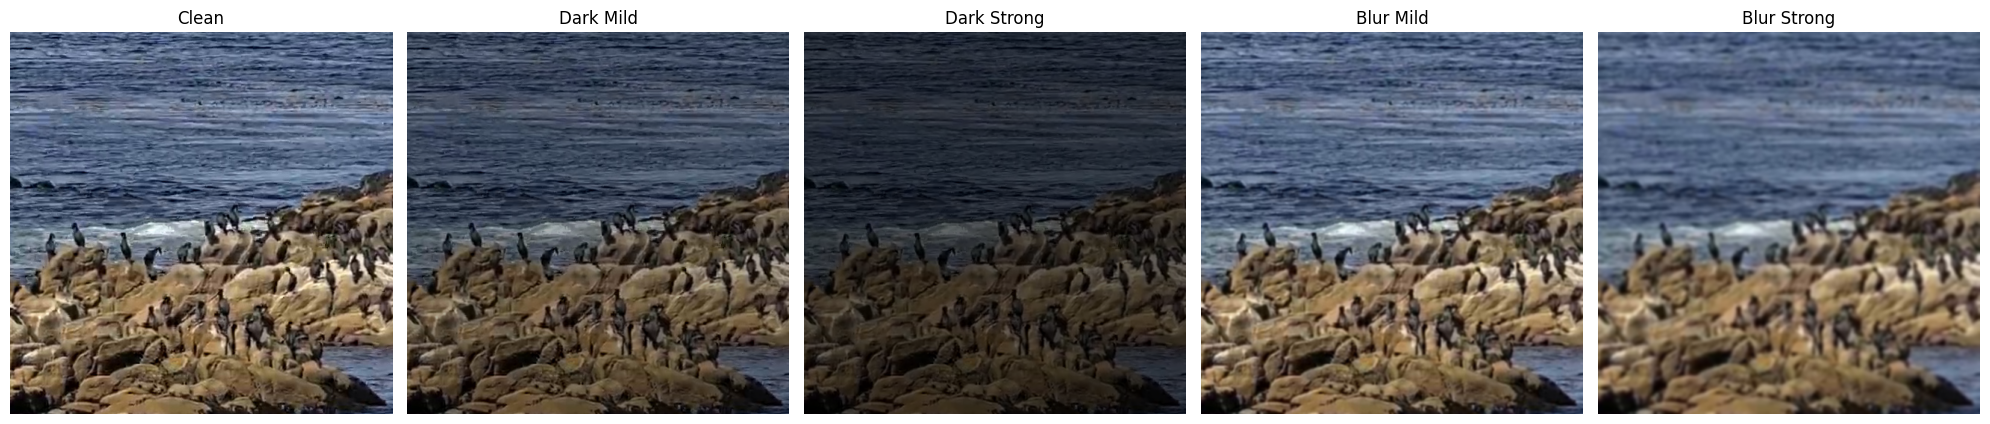

In [11]:
import matplotlib.pyplot as plt
from PIL import Image

# Use the same validation image for every condition.
example_relative = (
    validation_images[0]
    .relative_to(VAL_IMAGES)
    .with_suffix(".png")
)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, condition in zip(axes, CONDITIONS):
    image_path = (
        ROBUSTNESS_DIR / condition / "images" / "val" / example_relative
    )

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(condition.replace("_", " ").title())
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
from ultralytics import YOLO
import ultralytics
import pandas as pd
import json
import time
from IPython.display import display

if ultralytics.__version__ != "8.4.208":
    raise RuntimeError(
        "Use Ultralytics 8.4.208 to match the training experiments."
    )

EVAL_DIR = YOLO_DIR / "robustness_evaluation_v1"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_FILE = EVAL_DIR / "robustness_results.csv"
SETTINGS_FILE = EVAL_DIR / "evaluation_settings.json"

EVAL_SETTINGS = {
    "split": "val",
    "imgsz": 640,
    "batch": 8,
    "workers": 0,
    "device": "cpu",
    "conf": 0.001,
    "iou": 0.7,          # NMS overlap threshold, not the mAP matching threshold
    "max_det": 300,
    "augment": False,
    "half": False,
    "rect": True,
    "plots": False,
    "save_json": False,
    "verbose": False
}

evaluation_record = {
    "ultralytics_version": ultralytics.__version__,
    "settings": EVAL_SETTINGS,
    "models": {
        name: str(path.resolve())
        for name, path in MODEL_PATHS.items()
    },
    "conditions": CONDITIONS
}

# Prevent accidentally combining results from different configurations.
if SETTINGS_FILE.exists():
    saved_record = json.loads(SETTINGS_FILE.read_text(encoding="utf-8"))
    if saved_record != evaluation_record:
        raise ValueError(
            "Evaluation settings changed. Use a new EVAL_DIR "
            "rather than mixing different experiments."
        )
else:
    SETTINGS_FILE.write_text(
        json.dumps(evaluation_record, indent=2),
        encoding="utf-8"
    )

if RESULTS_FILE.exists():
    rows = pd.read_csv(RESULTS_FILE).to_dict("records")
else:
    rows = []

completed = {
    (row["model"], row["condition"])
    for row in rows
}

for model_name, weights_path in MODEL_PATHS.items():
    remaining = [
        condition for condition in CONDITIONS
        if (model_name, condition) not in completed
    ]

    if not remaining:
        print(f"Skipping {model_name}: all conditions completed.")
        continue

    model = YOLO(str(weights_path))

    for condition in remaining:
        print(f"\nEvaluating: {model_name} | {condition}")

        start = time.perf_counter()

        metrics = model.val(
            data=str(ROBUSTNESS_YAMLS[condition]),
            project=str(EVAL_DIR / "runs"),
            name=f"{model_name}_{condition}",
            exist_ok=True,
            **EVAL_SETTINGS
        )

        elapsed = time.perf_counter() - start

        rows.append({
            "model": model_name,
            "condition": condition,
            "map50": float(metrics.box.map50),
            "map50_95": float(metrics.box.map),
            "precision": float(metrics.box.mp),
            "recall": float(metrics.box.mr),
            "evaluation_wall_seconds": elapsed
        })

        # Save after every successful evaluation.
        pd.DataFrame(rows).to_csv(RESULTS_FILE, index=False)
        completed.add((model_name, condition))

        print(
            f"mAP@0.5: {metrics.box.map50:.4f} | "
            f"mAP@0.5–0.95: {metrics.box.map:.4f}"
        )

    del model

robustness_results = pd.DataFrame(rows)

comparison = robustness_results.pivot(
    index="condition",
    columns="model",
    values="map50"
).reindex(list(CONDITIONS))

print("\nValidation mAP@0.5 (%):")
display((comparison * 100).round(2))

print("\nResults saved to:", RESULTS_FILE)


Evaluating: baseline | clean
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.208  Python-3.13.12 torch-2.15.0+cpu CPU (Intel Core Ultra 5 125H)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1493.6±573.5 MB/s, size: 415.0 KB)
val: Scanning C:\Users\raksh\Desktop\CompVis\yolo_work\robustness_validation_v1\clean\labels\val... 291 images, 33 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 291/291 819.6it/s 0.4s0.1s
val: New cache created: C:\Users\raksh\Desktop\CompVis\yolo_work\robustness_validation_v1\clean\labels\val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 1.1it/s 34.8s1.7ss
                   all        291       1843      0.849      0.757      0.831      0.427
Speed: 3.7ms preprocess, 94.0ms inference, 0.0ms loss, 2.2ms postprocess per image
mAP@0.5: 0.8312 | mAP@0.5–0.95

model,baseline,flips,flips_brightness_contrast
condition,,,
clean,83.12,84.21,83.85
dark_mild,81.94,83.22,82.30
dark_strong,78.95,77.74,78.34
blur_mild,80.00,81.12,80.83
blur_strong,67.03,66.49,68.12



Results saved to: C:\Users\raksh\Desktop\CompVis\yolo_work\robustness_evaluation_v1\robustness_results.csv


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


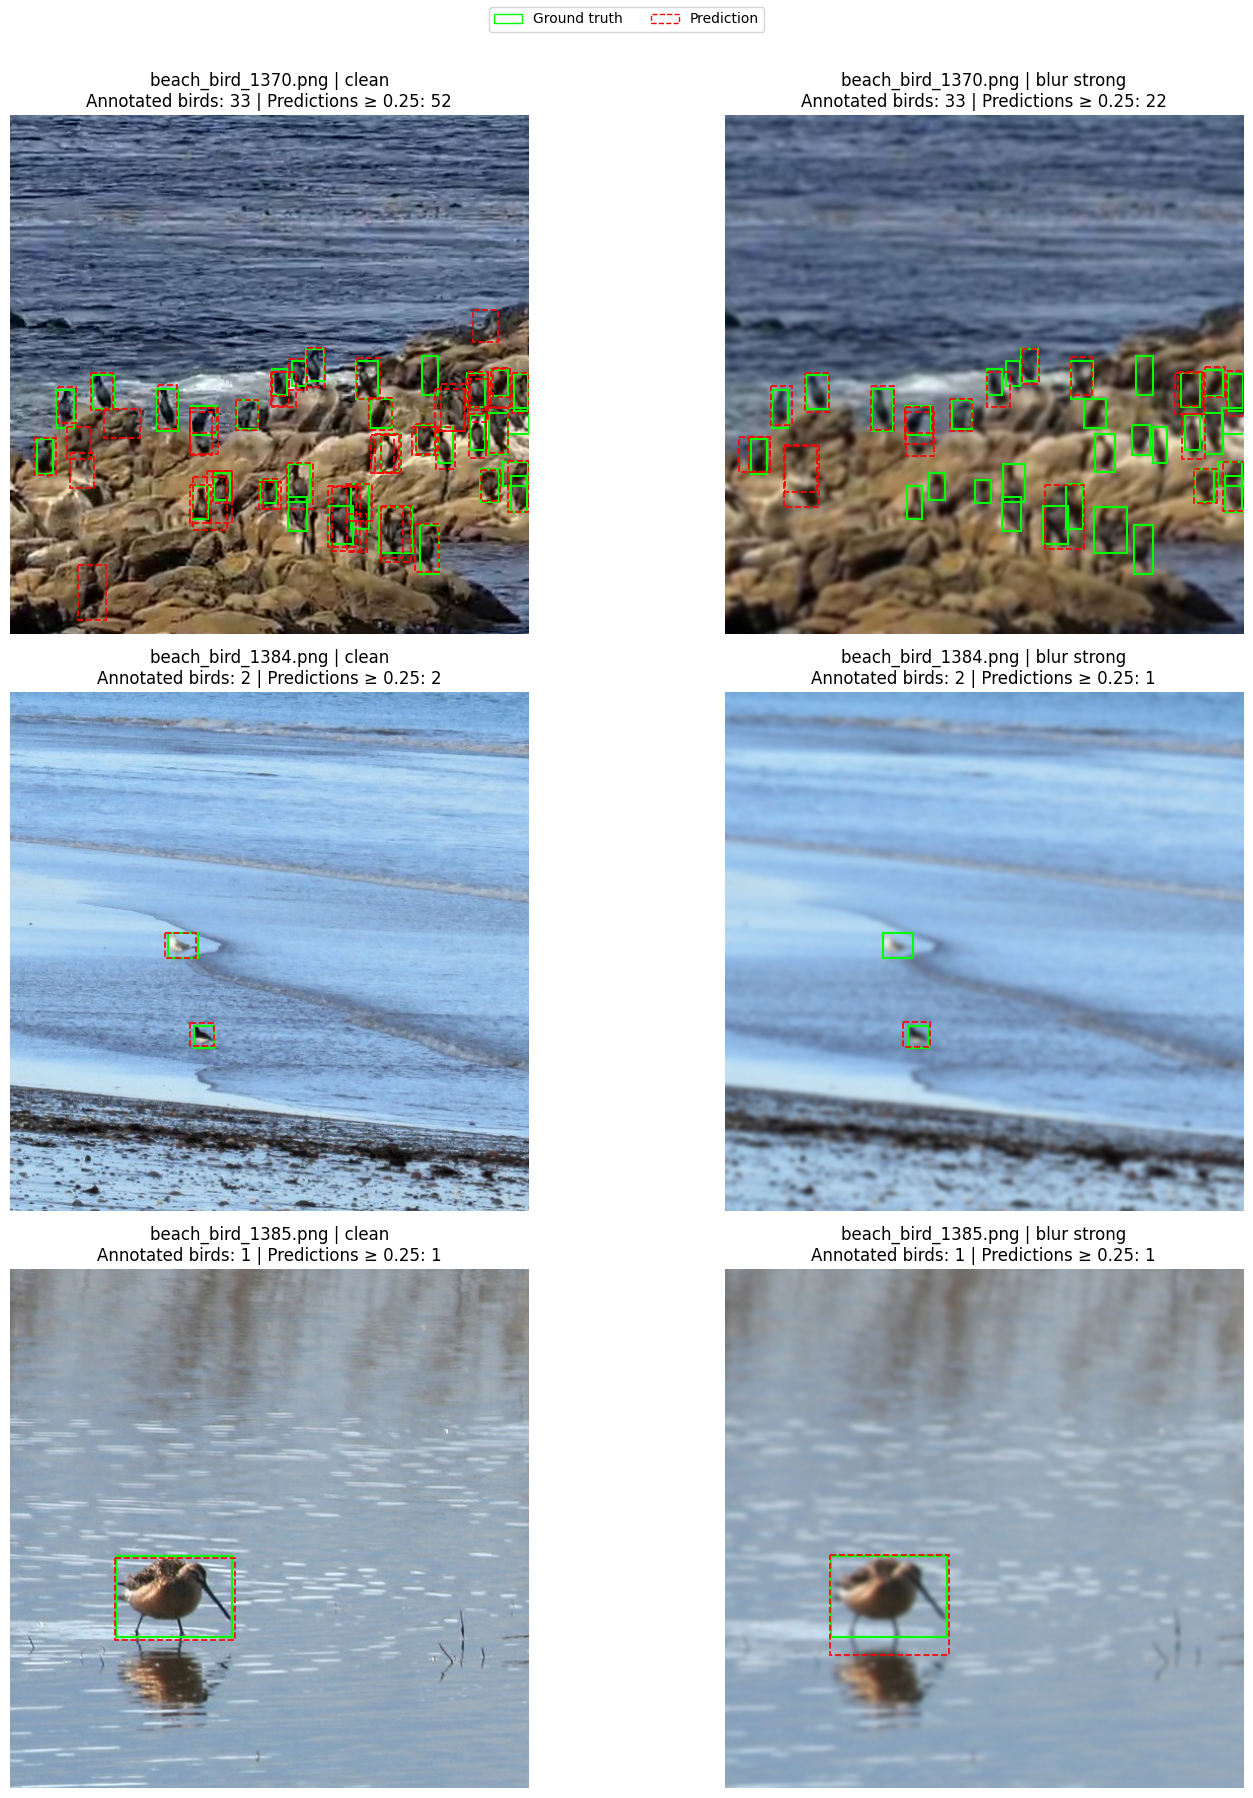

In [13]:
from pathlib import Path
from ultralytics import YOLO
from PIL import Image
from matplotlib.patches import Rectangle

import numpy as np
import matplotlib.pyplot as plt

YOLO_DIR = Path(r"C:\Users\raksh\Desktop\CompVis\yolo_work")
ROBUSTNESS_DIR = YOLO_DIR / "robustness_validation_v1"

appearance_weights = (
    YOLO_DIR / "runs"
    / "flip_brightness_contrast_seed42_20261112_132822"
    / "weights" / "best.pt"
)

if not appearance_weights.is_file():
    raise FileNotFoundError(appearance_weights)

inspection_model = YOLO(str(appearance_weights))

example_names = [
    "beach_bird_1370.png",
    "beach_bird_1384.png",
    "beach_bird_1385.png"
]

conditions_to_show = ["clean", "blur_strong"]
DISPLAY_CONFIDENCE = 0.25

fig, axes = plt.subplots(
    len(example_names), 2,
    figsize=(16, 18)
)

for row, filename in enumerate(example_names):
    for column, condition in enumerate(conditions_to_show):
        ax = axes[row, column]

        image_path = (
            ROBUSTNESS_DIR / condition / "images" / "val" / filename
        )
        label_path = (
            ROBUSTNESS_DIR / condition / "labels" / "val"
            / Path(filename).with_suffix(".txt")
        )

        if not image_path.is_file() or not label_path.is_file():
            raise FileNotFoundError(
                f"Missing image or label for {condition}: {filename}"
            )

        with Image.open(image_path) as source:
            image = source.convert("RGB")

        width, height = image.size
        ax.imshow(image)

        text = label_path.read_text(encoding="utf-8").strip()
        ground_truth = (
            np.array([
                list(map(float, line.split()))
                for line in text.splitlines()
            ])
            if text else np.empty((0, 5))
        )

        # Draw the ground truth boxes in green.
        for _, cx, cy, bw, bh in ground_truth:
            ax.add_patch(Rectangle(
                ((cx - bw / 2) * width, (cy - bh / 2) * height),
                bw * width,
                bh * height,
                fill=False,
                edgecolor="lime",
                linewidth=1.5
            ))

        prediction = inspection_model.predict(
            source=str(image_path),
            imgsz=640,
            conf=DISPLAY_CONFIDENCE,
            iou=0.7,
            max_det=300,
            device="cpu",
            augment=False,
            half=False,
            verbose=False
        )[0]

        predicted_boxes = prediction.boxes.xyxy.cpu().numpy()

        # Draw predictions in red, without text clutter.
        for x1, y1, x2, y2 in predicted_boxes:
            ax.add_patch(Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor="red",
                linewidth=1.2,
                linestyle="--"
            ))

        ax.set_title(
            f"{filename} | {condition.replace('_', ' ')}\n"
            f"Annotated birds: {len(ground_truth)} | "
            f"Predictions ≥ {DISPLAY_CONFIDENCE}: {len(predicted_boxes)}"
        )
        ax.axis("off")

fig.legend(
    handles=[
        Rectangle((0, 0), 1, 1, fill=False, edgecolor="lime",
                  label="Ground truth"),
        Rectangle((0, 0), 1, 1, fill=False, edgecolor="red",
                  linestyle="--", label="Prediction")
    ],
    loc="upper center",
    ncol=2
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [14]:
import random
import numpy as np
from PIL import Image, ImageFilter


class RandomGaussianBlur:
    """Blur the image while keeping bounding boxes unchanged."""

    def __init__(self, p=0.3, radius_min=0.5, radius_max=2.0):
        self.p = p
        self.radius_min = radius_min
        self.radius_max = radius_max

    def __call__(self, labels):
        if random.random() < self.p:
            radius = random.uniform(self.radius_min, self.radius_max)

            # Gaussian blur acts independently on each colour channel.
            # Preserve Ultralytics' existing channel order.
            image = Image.fromarray(labels["img"])
            image = image.filter(
                ImageFilter.GaussianBlur(radius=radius)
            )
            labels["img"] = np.asarray(image).copy()

        return labels

    def __repr__(self):
        return (
            f"RandomGaussianBlur(p={self.p}, "
            f"radius=({self.radius_min}, {self.radius_max}))"
        )


class BlurRobustTrainer(FlipBrightnessContrastTrainer):
    """Existing appearance experiment plus Gaussian blur."""

    def build_dataset(self, img_path, mode="train", batch=None):
        dataset = super().build_dataset(
            img_path,
            mode=mode,
            batch=batch
        )

        if mode == "train":
            dataset.transforms.transforms.insert(
                0,
                RandomGaussianBlur(
                    p=0.3,
                    radius_min=0.5,
                    radius_max=2.0
                )
            )

            print("\nFinal blur experiment pipeline:")
            print(dataset.transforms)

        return dataset

In [15]:
from pathlib import Path
from datetime import datetime
from ultralytics import YOLO

import ultralytics
import yaml
import json
import time

YOLO_DIR = Path(r"C:\Users\raksh\Desktop\CompVis\yolo_work")

appearance_run = (
    YOLO_DIR / "runs"
    / "flip_brightness_contrast_seed42_20261112_132822"
)

if ultralytics.__version__ != "8.4.208":
    raise RuntimeError(
        "Use Ultralytics 8.4.208 to match the previous experiments."
    )

with (appearance_run / "args.yaml").open(
    "r", encoding="utf-8"
) as file:
    blur_settings = yaml.safe_load(file)

blur_settings.pop("save_dir", None)

BLUR_RUN_NAME = (
    "flip_appearance_blur_seed42_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)

blur_settings.update({
    "model": "yolo11n.pt",
    "data": str((YOLO_DIR / "bird_dataset.yaml").resolve()),
    "project": str((YOLO_DIR / "runs").resolve()),
    "name": BLUR_RUN_NAME,
    "epochs": 10,
    "fliplr": 0.5,
    "resume": False,
    "exist_ok": False
})

blur_model = YOLO("yolo11n.pt")

start_time = time.perf_counter()

blur_results = blur_model.train(
    trainer=BlurRobustTrainer,
    **blur_settings
)

blur_seconds = time.perf_counter() - start_time

BLUR_RUN_DIR = Path(blur_model.trainer.save_dir)
BLUR_WEIGHTS = BLUR_RUN_DIR / "weights" / "best.pt"

blur_summary = {
    "experiment": "flip_appearance_blur",
    "model": "yolo11n",
    "initial_weights": "yolo11n.pt",
    "trainer": "BlurRobustTrainer",
    "horizontal_flip_probability": 0.5,
    "appearance_probability": 0.5,
    "contrast_factor_range": [0.8, 1.2],
    "brightness_offset_range_pixels": [-25.5, 25.5],
    "blur_probability": 0.3,
    "blur_radius_range_pixels": [0.5, 2.0],
    "blur_location": (
        "Loaded training image, before LetterBox; "
        "loading may already resize the original image."
    ),
    "epochs_requested": 10,
    "seed": blur_settings["seed"],
    "ultralytics_version": ultralytics.__version__,
    "wall_time_seconds": blur_seconds,
    "wall_time_minutes": blur_seconds / 60,
    "best_weights": str(BLUR_WEIGHTS.resolve()),
    "note": "Wall time includes setup, validation and any pauses."
}

with (BLUR_RUN_DIR / "run_summary.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(blur_summary, file, indent=2)

print(f"\nRun duration: {blur_seconds / 60:.2f} minutes")
print("Results folder:", BLUR_RUN_DIR)
print("Best model:", BLUR_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.212 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.208  Python-3.13.12 torch-2.15.0+cpu CPU (Intel Core Ultra 5 125H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\raksh\Desktop\CompVis\yolo_work\bird_dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, m

In [16]:
from pathlib import Path
from ultralytics import YOLO
import ultralytics
import pandas as pd
import json
import time
from IPython.display import display

YOLO_DIR = Path(r"C:\Users\raksh\Desktop\CompVis\yolo_work")

PREVIOUS_EVAL_DIR = YOLO_DIR / "robustness_evaluation_v1"
ROBUSTNESS_DIR = YOLO_DIR / "robustness_validation_v1"
BLUR_EVAL_DIR = YOLO_DIR / "robustness_blur_model_v1"

BLUR_WEIGHTS = (
    YOLO_DIR / "runs"
    / "flip_appearance_blur_seed42_20261114_232048"
    / "weights" / "best.pt"
)

if not BLUR_WEIGHTS.is_file():
    raise FileNotFoundError(BLUR_WEIGHTS)

with (PREVIOUS_EVAL_DIR / "evaluation_settings.json").open(
    encoding="utf-8"
) as file:
    previous_record = json.load(file)

if ultralytics.__version__ != previous_record["ultralytics_version"]:
    raise RuntimeError(
        "Use the same Ultralytics version as the previous evaluations: "
        + previous_record["ultralytics_version"]
    )

eval_settings = previous_record["settings"].copy()
conditions = previous_record["conditions"]

BLUR_EVAL_DIR.mkdir(parents=True, exist_ok=True)
results_path = BLUR_EVAL_DIR / "robustness_results.csv"
settings_path = BLUR_EVAL_DIR / "evaluation_settings.json"

record = {
    "ultralytics_version": ultralytics.__version__,
    "settings": eval_settings,
    "model": str(BLUR_WEIGHTS.resolve()),
    "conditions": conditions
}

if settings_path.exists():
    saved = json.loads(settings_path.read_text(encoding="utf-8"))
    if saved != record:
        raise ValueError("Settings changed. Use a new evaluation folder.")
else:
    settings_path.write_text(
        json.dumps(record, indent=2),
        encoding="utf-8"
    )

rows = (
    pd.read_csv(results_path).to_dict("records")
    if results_path.exists()
    else []
)

completed = {row["condition"] for row in rows}
model = YOLO(str(BLUR_WEIGHTS))

for condition in conditions:
    if condition in completed:
        print(f"Skipping completed condition: {condition}")
        continue

    condition_yaml = ROBUSTNESS_DIR / condition / "dataset.yaml"

    if not condition_yaml.is_file():
        raise FileNotFoundError(condition_yaml)

    print(f"\nEvaluating blur model: {condition}")
    start = time.perf_counter()

    metrics = model.val(
        data=str(condition_yaml),
        project=str(BLUR_EVAL_DIR / "runs"),
        name=condition,
        exist_ok=True,
        **eval_settings
    )

    rows.append({
        "model": "flips_appearance_blur",
        "condition": condition,
        "map50": float(metrics.box.map50),
        "map50_95": float(metrics.box.map),
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "evaluation_wall_seconds": time.perf_counter() - start
    })

    pd.DataFrame(rows).to_csv(results_path, index=False)
    completed.add(condition)

# Combine the previous three models with the new model.
previous_results = pd.read_csv(
    PREVIOUS_EVAL_DIR / "robustness_results.csv"
)

combined = pd.concat(
    [previous_results, pd.DataFrame(rows)],
    ignore_index=True
)

combined.to_csv(
    BLUR_EVAL_DIR / "all_four_models_robustness.csv",
    index=False
)

# Calculate each model's drop from its own clean performance.
clean_scores = (
    combined[combined["condition"] == "clean"]
    .set_index("model")["map50"]
)

combined["map50_drop_pp"] = (
    combined["model"].map(clean_scores) - combined["map50"]
) * 100

combined.to_csv(
    BLUR_EVAL_DIR / "all_four_models_with_drops.csv",
    index=False
)

print("\nmAP@0.5 (%):")
display(
    (
        combined.pivot(
            index="condition",
            columns="model",
            values="map50"
        ).reindex(list(conditions)) * 100
    ).round(2)
)

print("\nDrop from each model's clean mAP@0.5 (percentage points):")
display(
    combined.pivot(
        index="condition",
        columns="model",
        values="map50_drop_pp"
    ).reindex(list(conditions)).round(2)
)

print("\nSaved to:", BLUR_EVAL_DIR)


Evaluating blur model: clean
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.208  Python-3.13.12 torch-2.15.0+cpu CPU (Intel Core Ultra 5 125H)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.2±0.1 ms, read: 284.3±108.9 MB/s, size: 423.4 KB)
val: Scanning C:\Users\raksh\Desktop\CompVis\yolo_work\robustness_validation_v1\clean\labels\val.cache... 291 images, 33 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 291/291 277.0Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 1.2it/s 31.4s0.7ss
                   all        291       1843      0.845      0.762      0.835      0.429
Speed: 3.4ms preprocess, 82.9ms inference, 0.0ms loss, 1.7ms postprocess per image

Evaluating blur model: dark_mild
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.208

model,baseline,flips,flips_appearance_blur,flips_brightness_contrast
condition,,,,
clean,83.12,84.21,83.55,83.85
dark_mild,81.94,83.22,82.69,82.30
dark_strong,78.95,77.74,79.17,78.34
blur_mild,80.00,81.12,83.11,80.83
blur_strong,67.03,66.49,75.49,68.12



Drop from each model's clean mAP@0.5 (percentage points):


model,baseline,flips,flips_appearance_blur,flips_brightness_contrast
condition,,,,
clean,0.00,0.00,0.00,0.00
dark_mild,1.18,0.99,0.86,1.56
dark_strong,4.17,6.47,4.38,5.51
blur_mild,3.12,3.08,0.44,3.03
blur_strong,16.10,17.72,8.06,15.73



Saved to: C:\Users\raksh\Desktop\CompVis\yolo_work\robustness_blur_model_v1


In [17]:
from pathlib import Path
from PIL import Image, ImageFilter
from tqdm.auto import tqdm

import numpy as np
import yaml
import json
import shutil
import hashlib

YOLO_DIR = Path(r"C:\Users\raksh\Desktop\CompVis\yolo_work")
FINAL_DIR = YOLO_DIR / "final_test_v1"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

with (YOLO_DIR / "bird_dataset.yaml").open(encoding="utf-8") as file:
    dataset_config = yaml.safe_load(file)

DATA_ROOT = Path(dataset_config["path"])
TEST_IMAGES = DATA_ROOT / "images" / "test"
TEST_LABELS = DATA_ROOT / "labels" / "test"

with (
    YOLO_DIR / "robustness_evaluation_v1" / "evaluation_settings.json"
).open(encoding="utf-8") as file:
    validation_protocol = json.load(file)

CONDITIONS = validation_protocol["conditions"]
TEST_SETTINGS = validation_protocol["settings"].copy()
TEST_SETTINGS["split"] = "test"

MODEL_PATHS = {
    "baseline": (
        YOLO_DIR / "runs" / "baseline_seed42_20261111_140300"
        / "weights" / "best.pt"
    ),
    "flips": (
        YOLO_DIR / "runs" / "horizontal_flip_seed42_20261111_231306"
        / "weights" / "best.pt"
    ),
    "flips_brightness_contrast": (
        YOLO_DIR / "runs"
        / "flip_brightness_contrast_seed42_20261112_132822"
        / "weights" / "best.pt"
    ),
    "flips_appearance_blur": (
        YOLO_DIR / "runs"
        / "flip_appearance_blur_seed42_20261114_232048"
        / "weights" / "best.pt"
    )
}

for name, path in MODEL_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f"{name}: {path}")

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

test_images = sorted(
    p for p in TEST_IMAGES.rglob("*")
    if p.suffix.lower() in extensions
)

if not test_images:
    raise FileNotFoundError(f"No test images found: {TEST_IMAGES}")

relative_paths = [p.relative_to(TEST_IMAGES) for p in test_images]
output_names = [p.with_suffix(".png").as_posix() for p in relative_paths]

if len(output_names) != len(set(output_names)):
    raise ValueError("Duplicate filenames after PNG conversion.")

for relative in relative_paths:
    label = TEST_LABELS / relative.with_suffix(".txt")
    if not label.is_file():
        raise FileNotFoundError(f"Missing test label: {label}")


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


# Record exact checkpoints, settings and source data before evaluation.
protocol = {
    "split": "test",
    "ultralytics_version": validation_protocol["ultralytics_version"],
    "settings": TEST_SETTINGS,
    "conditions": CONDITIONS,
    "checkpoint_hashes": {
        name: sha256_file(path)
        for name, path in MODEL_PATHS.items()
    },
    "test_files": [
        {
            "image": relative.as_posix(),
            "image_sha256": sha256_file(TEST_IMAGES / relative),
            "label_sha256": sha256_file(
                TEST_LABELS / relative.with_suffix(".txt")
            )
        }
        for relative in relative_paths
    ],
    "selection_rule": (
        "Evaluate all four fixed variants; "
        "do not tune using test results."
    )
}

protocol_path = FINAL_DIR / "test_protocol.json"

if protocol_path.exists():
    previous = json.loads(protocol_path.read_text(encoding="utf-8"))
    if previous != protocol:
        raise ValueError(
            "The frozen protocol has changed. Stop and check the difference."
        )
else:
    protocol_path.write_text(
        json.dumps(protocol, indent=2),
        encoding="utf-8"
    )

TEST_YAMLS = {}

for condition, settings in CONDITIONS.items():
    condition_root = FINAL_DIR / "datasets" / condition

    for source_path, relative in tqdm(
        list(zip(test_images, relative_paths)),
        desc=condition
    ):
        image_destination = (
            condition_root / "images" / "test"
            / relative.with_suffix(".png")
        )
        label_destination = (
            condition_root / "labels" / "test"
            / relative.with_suffix(".txt")
        )

        image_destination.parent.mkdir(parents=True, exist_ok=True)
        label_destination.parent.mkdir(parents=True, exist_ok=True)

        with Image.open(source_path) as source:
            image = source.convert("RGB")

        if settings["type"] == "dark":
            pixels = np.asarray(image).astype(np.float32)
            image = Image.fromarray(
                np.clip(
                    pixels * settings["factor"], 0, 255
                ).astype(np.uint8)
            )

        elif settings["type"] == "blur":
            image = image.filter(
                ImageFilter.GaussianBlur(radius=settings["radius"])
            )

        image.save(image_destination)

        shutil.copy2(
            TEST_LABELS / relative.with_suffix(".txt"),
            label_destination
        )

    config = {
        "path": str(condition_root.resolve()),
        "train": str((DATA_ROOT / "images" / "train").resolve()),
        "val": str((DATA_ROOT / "images" / "val").resolve()),
        "test": "images/test",
        "nc": 1,
        "names": {0: "bird"}
    }

    yaml_path = condition_root / "dataset.yaml"
    with yaml_path.open("w", encoding="utf-8") as file:
        yaml.safe_dump(config, file, sort_keys=False)

    TEST_YAMLS[condition] = yaml_path

print(f"\nPrepared {len(test_images)} test images per condition.")
print("Expected from the project brief: 240.")
print("Protocol saved:", protocol_path)

clean:   0%|          | 0/240 [00:00<?, ?it/s]

dark_mild:   0%|          | 0/240 [00:00<?, ?it/s]

dark_strong:   0%|          | 0/240 [00:00<?, ?it/s]

blur_mild:   0%|          | 0/240 [00:00<?, ?it/s]

blur_strong:   0%|          | 0/240 [00:00<?, ?it/s]


Prepared 240 test images per condition.
Expected from the project brief: 240.
Protocol saved: C:\Users\raksh\Desktop\CompVis\yolo_work\final_test_v1\test_protocol.json


In [18]:
from ultralytics import YOLO
from IPython.display import display

import ultralytics
import pandas as pd
import time

if ultralytics.__version__ != protocol["ultralytics_version"]:
    raise RuntimeError(
        "Ultralytics version differs from the frozen protocol."
    )

results_file = FINAL_DIR / "test_results.csv"

rows = (
    pd.read_csv(results_file).to_dict("records")
    if results_file.exists()
    else []
)

completed = {
    (row["model"], row["condition"])
    for row in rows
}

for model_name, checkpoint in MODEL_PATHS.items():
    pending = [
        condition for condition in CONDITIONS
        if (model_name, condition) not in completed
    ]

    if not pending:
        print(f"Already completed: {model_name}")
        continue

    model = YOLO(str(checkpoint))

    for condition in pending:
        print(f"\nFinal test: {model_name} | {condition}")
        start = time.perf_counter()

        metrics = model.val(
            data=str(TEST_YAMLS[condition]),
            project=str(FINAL_DIR / "runs"),
            name=f"{model_name}_{condition}",
            exist_ok=True,
            **TEST_SETTINGS
        )

        rows.append({
            "model": model_name,
            "condition": condition,
            "map50": float(metrics.box.map50),
            "map50_95": float(metrics.box.map),
            "precision": float(metrics.box.mp),
            "recall": float(metrics.box.mr),
            "evaluation_wall_seconds": time.perf_counter() - start
        })

        pd.DataFrame(rows).to_csv(results_file, index=False)
        completed.add((model_name, condition))

    del model

test_results = pd.DataFrame(rows)

clean_scores = (
    test_results[test_results["condition"] == "clean"]
    .set_index("model")["map50"]
)

test_results["map50_drop_pp"] = (
    test_results["model"].map(clean_scores)
    - test_results["map50"]
) * 100

test_results.to_csv(
    FINAL_DIR / "test_results_with_drops.csv",
    index=False
)

print("\nFinal test mAP@0.5 (%):")
display(
    (
        test_results.pivot(
            index="condition",
            columns="model",
            values="map50"
        ).reindex(list(CONDITIONS)) * 100
    ).round(2)
)

print("\nFinal test mAP@0.5–0.95 (%):")
display(
    (
        test_results.pivot(
            index="condition",
            columns="model",
            values="map50_95"
        ).reindex(list(CONDITIONS)) * 100
    ).round(2)
)

print("\nSaved to:", FINAL_DIR)



Final test: baseline | clean
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.208  Python-3.13.12 torch-2.15.0+cpu CPU (Intel Core Ultra 5 125H)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 719.8±593.5 MB/s, size: 320.0 KB)
val: Scanning C:\Users\raksh\Desktop\CompVis\yolo_work\final_test_v1\datasets\clean\labels\test... 240 images, 27 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 240/240 715.4it/s 0.3s0.1s
val: New cache created: C:\Users\raksh\Desktop\CompVis\yolo_work\final_test_v1\datasets\clean\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 1.1it/s 28.1s1.0ss
                   all        240       1518       0.82      0.731      0.807      0.423
Speed: 3.5ms preprocess, 90.7ms inference, 0.0ms loss, 1.6ms postprocess per image

Final test: baseline | dark_mild

model,baseline,flips,flips_appearance_blur,flips_brightness_contrast
condition,,,,
clean,80.74,84.73,84.31,84.87
dark_mild,80.25,84.20,83.96,84.65
dark_strong,77.94,77.76,81.17,79.92
blur_mild,78.93,83.01,83.70,83.58
blur_strong,66.81,70.32,77.80,71.83



Final test mAP@0.5–0.95 (%):


model,baseline,flips,flips_appearance_blur,flips_brightness_contrast
condition,,,,
clean,42.29,45.47,45.70,46.10
dark_mild,42.34,45.25,45.23,45.66
dark_strong,40.47,41.60,43.14,43.04
blur_mild,40.73,44.14,44.56,44.73
blur_strong,31.76,35.11,39.27,35.36



Saved to: C:\Users\raksh\Desktop\CompVis\yolo_work\final_test_v1


In [19]:
from pathlib import Path
from ultralytics import YOLO

import ultralytics
import torch
import cv2
import numpy as np
import pandas as pd
import random
import time
import json
import platform

from datetime import datetime
from IPython.display import display

YOLO_DIR = Path(r"C:\Users\raksh\Desktop\CompVis\yolo_work")

MODEL_PATHS = {
    "baseline": (
        YOLO_DIR / "runs" / "baseline_seed42_20261111_140300"
        / "weights" / "best.pt"
    ),
    "flips": (
        YOLO_DIR / "runs" / "horizontal_flip_seed42_20261111_231306"
        / "weights" / "best.pt"
    ),
    "flips_brightness_contrast": (
        YOLO_DIR / "runs"
        / "flip_brightness_contrast_seed42_20261112_132822"
        / "weights" / "best.pt"
    ),
    "flips_appearance_blur": (
        YOLO_DIR / "runs"
        / "flip_appearance_blur_seed42_20261114_232048"
        / "weights" / "best.pt"
    )
}

CLEAN_TEST_DIR = (
    YOLO_DIR / "final_test_v1" / "datasets"
    / "clean" / "images" / "test"
)

if ultralytics.__version__ != "8.4.208":
    raise RuntimeError("Use Ultralytics 8.4.208 to match the experiments.")

for name, path in MODEL_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f"{name}: {path}")

image_paths = sorted(CLEAN_TEST_DIR.rglob("*.png"))

if len(image_paths) < 30:
    raise ValueError("Expected at least 30 clean test images.")

# Fixed sample shared by every model.
selected_paths = random.Random(42).sample(image_paths, 30)

# Load images before starting any timers.
images = []
for path in selected_paths:
    image = cv2.imread(str(path))
    if image is None:
        raise ValueError(f"Could not read image: {path}")
    images.append(image)

REPEATS = 3
WARMUP_CALLS = 5

PREDICT_SETTINGS = {
    "imgsz": 640,
    "batch": 1,
    "device": "cpu",
    "conf": 0.001,
    "iou": 0.7,
    "max_det": 300,
    "augment": False,
    "half": False,
    "rect": True,
    "verbose": False,
    "save": False
}

BENCHMARK_DIR = (
    YOLO_DIR / "inference_benchmark"
    / datetime.now().strftime("%Y%m%d_%H%M%S")
)
BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)

# Fix the CPU thread count across all models.
previous_threads = torch.get_num_threads()
BENCHMARK_THREADS = min(4, previous_threads)
torch.set_num_threads(BENCHMARK_THREADS)

timing_rows = []
execution_order = []

try:
    for repeat in range(1, REPEATS + 1):
        # Vary model order to reduce systematic ordering effects.
        model_order = list(MODEL_PATHS)
        random.Random(42 + repeat).shuffle(model_order)

        # All models see the same image order within this repeat.
        image_order = list(range(len(images)))
        random.Random(100 + repeat).shuffle(image_order)

        execution_order.append({
            "repeat": repeat,
            "models": model_order,
            "image_indices": image_order
        })

        for model_name in model_order:
            print(f"Repeat {repeat}/{REPEATS}: {model_name}")

            model = YOLO(str(MODEL_PATHS[model_name]))

            # Exclude initial setup and warm-up from recorded timings.
            for index in image_order[:WARMUP_CALLS]:
                model.predict(
                    source=images[index],
                    **PREDICT_SETTINGS
                )

            for index in image_order:
                start = time.perf_counter()

                predictions = model.predict(
                    source=images[index],
                    **PREDICT_SETTINGS
                )

                elapsed_ms = (time.perf_counter() - start) * 1000

                timing_rows.append({
                    "model": model_name,
                    "repeat": repeat,
                    "image": selected_paths[index].relative_to(
                        CLEAN_TEST_DIR
                    ).as_posix(),
                    "latency_ms": elapsed_ms
                })

            # Save progress after each model and repeat.
            pd.DataFrame(timing_rows).to_csv(
                BENCHMARK_DIR / "raw_timings.csv",
                index=False
            )

            del predictions
            del model

finally:
    torch.set_num_threads(previous_threads)

timings = pd.DataFrame(timing_rows)

speed_summary = (
    timings.groupby("model", sort=False)
    .agg(
        measurements=("latency_ms", "size"),
        mean_ms_per_image=("latency_ms", "mean"),
        median_ms_per_image=("latency_ms", "median"),
        p95_ms_per_image=(
            "latency_ms",
            lambda values: np.percentile(values, 95)
        )
    )
    .reset_index()
)

# Serial throughput estimate, not batched throughput.
speed_summary["serial_images_per_second"] = (
    1000 / speed_summary["mean_ms_per_image"]
)

speed_summary.to_csv(
    BENCHMARK_DIR / "speed_summary.csv",
    index=False
)

metadata = {
    "measurement": (
        "CPU batch-1 prediction-call latency; includes preprocessing, "
        "inference, postprocessing and Python overhead; "
        "excludes disk reads, model loading and warm-up."
    ),
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "processor": platform.processor(),
    "torch_version": torch.__version__,
    "ultralytics_version": ultralytics.__version__,
    "torch_cpu_threads": BENCHMARK_THREADS,
    "repeats": REPEATS,
    "warmup_calls_per_model_per_repeat": WARMUP_CALLS,
    "settings": PREDICT_SETTINGS,
    "images": [
        path.relative_to(CLEAN_TEST_DIR).as_posix()
        for path in selected_paths
    ],
    "execution_order": execution_order
}

with (BENCHMARK_DIR / "benchmark_settings.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=2)

display(speed_summary.round(2))
print("\nSaved to:", BENCHMARK_DIR)

Repeat 1/3: flips_brightness_contrast
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' ins

,model,measurements,mean_ms_per_image,median_ms_per_image,p95_ms_per_image,serial_images_per_second
0,flips_brightness_contrast,90,201.73,129.18,510.01,4.96
1,flips_appearance_blur,90,149.49,132.67,228.05,6.69
2,flips,90,178.25,153.08,329.03,5.61
3,baseline,90,152.00,133.17,246.39,6.58



Saved to: C:\Users\raksh\Desktop\CompVis\yolo_work\inference_benchmark\20261115_153901


In [20]:
from pathlib import Path
from ultralytics import YOLO
from PIL import Image
from tqdm.auto import tqdm

import numpy as np
import pandas as pd

YOLO_DIR = Path(r"C:\Users\raksh\Desktop\CompVis\yolo_work")
TEST_DATA_DIR = YOLO_DIR / "final_test_v1" / "datasets"

ANALYSIS_DIR = YOLO_DIR / "failure_analysis_v1"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

ANALYSIS_MODELS = {
    "before_blur_training": (
        YOLO_DIR / "runs"
        / "flip_brightness_contrast_seed42_20261112_132822"
        / "weights" / "best.pt"
    ),
    "after_blur_training": (
        YOLO_DIR / "runs"
        / "flip_appearance_blur_seed42_20261114_232048"
        / "weights" / "best.pt"
    )
}

CONFIDENCE = 0.25
MATCH_IOU = 0.5


def load_ground_truth(label_path, width, height):
    text = label_path.read_text(encoding="utf-8").strip()

    if not text:
        return np.empty((0, 4), dtype=float)

    labels = np.array([
        list(map(float, line.split()))
        for line in text.splitlines()
    ])

    cx, cy, bw, bh = labels[:, 1:5].T

    return np.column_stack([
        (cx - bw / 2) * width,
        (cy - bh / 2) * height,
        (cx + bw / 2) * width,
        (cy + bh / 2) * height
    ])


def box_iou_with_targets(box, targets):
    if len(targets) == 0:
        return np.empty(0)

    top_left = np.maximum(box[:2], targets[:, :2])
    bottom_right = np.minimum(box[2:], targets[:, 2:])

    intersection = np.clip(
        bottom_right - top_left, 0, None
    ).prod(axis=1)

    box_area = np.clip(box[2:] - box[:2], 0, None).prod()
    target_areas = np.clip(
        targets[:, 2:] - targets[:, :2], 0, None
    ).prod(axis=1)

    union = box_area + target_areas - intersection
    return intersection / np.maximum(union, 1e-9)


def match_predictions(predicted_boxes, scores, ground_truth):
    # Each ground truth bird can match at most one prediction.
    matched = np.zeros(len(ground_truth), dtype=bool)
    true_positives = 0

    for index in np.argsort(-scores):
        available = np.flatnonzero(~matched)

        if len(available) == 0:
            continue

        overlaps = box_iou_with_targets(
            predicted_boxes[index],
            ground_truth[available]
        )

        best = int(np.argmax(overlaps))

        if overlaps[best] >= MATCH_IOU:
            matched[available[best]] = True
            true_positives += 1

    false_positives = len(predicted_boxes) - true_positives
    false_negatives = len(ground_truth) - true_positives

    return true_positives, false_positives, false_negatives


all_rows = []

for model_name, checkpoint in ANALYSIS_MODELS.items():
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)

    model = YOLO(str(checkpoint))

    for condition in ["clean", "blur_strong"]:
        image_dir = TEST_DATA_DIR / condition / "images" / "test"
        label_dir = TEST_DATA_DIR / condition / "labels" / "test"

        images = sorted(image_dir.rglob("*.png"))

        if not images:
            raise FileNotFoundError(f"No images in {image_dir}")

        condition_rows = []

        for image_path in tqdm(
            images, desc=f"{model_name}: {condition}"
        ):
            relative = image_path.relative_to(image_dir)
            label_path = label_dir / relative.with_suffix(".txt")

            with Image.open(image_path) as image:
                width, height = image.size

            ground_truth = load_ground_truth(
                label_path, width, height
            )

            prediction = model.predict(
                source=str(image_path),
                imgsz=640,
                conf=CONFIDENCE,
                iou=0.7,
                max_det=300,
                device="cpu",
                augment=False,
                half=False,
                rect=True,
                verbose=False,
                save=False
            )[0]

            boxes = prediction.boxes.xyxy.cpu().numpy()
            scores = prediction.boxes.conf.cpu().numpy()

            tp, fp, fn = match_predictions(
                boxes, scores, ground_truth
            )

            condition_rows.append({
                "model": model_name,
                "condition": condition,
                "image": relative.as_posix(),
                "ground_truth_birds": len(ground_truth),
                "predictions": len(boxes),
                "true_positives": tp,
                "false_positives": fp,
                "false_negatives": fn,
                "total_errors": fp + fn
            })

        # Separate files preserve completed combinations.
        pd.DataFrame(condition_rows).to_csv(
            ANALYSIS_DIR / f"{model_name}_{condition}.csv",
            index=False
        )

        all_rows.extend(condition_rows)

    del model

failure_results = pd.DataFrame(all_rows)

failure_results.to_csv(
    ANALYSIS_DIR / "per_image_errors.csv",
    index=False
)

error_summary = (
    failure_results.groupby(["model", "condition"])[
        ["ground_truth_birds", "true_positives",
         "false_positives", "false_negatives"]
    ]
    .sum()
    .reset_index()
)

tp = error_summary["true_positives"]
fp = error_summary["false_positives"]
fn = error_summary["false_negatives"]

error_summary["precision_at_025"] = tp / (tp + fp).replace(0, np.nan)
error_summary["recall_at_025"] = tp / (tp + fn).replace(0, np.nan)

error_summary.to_csv(
    ANALYSIS_DIR / "error_summary.csv",
    index=False
)

display(error_summary.round(4))
print("\nSaved to:", ANALYSIS_DIR)

before_blur_training: clean:   0%|          | 0/240 [00:00<?, ?it/s]

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and

before_blur_training: blur_strong:   0%|          | 0/240 [00:00<?, ?it/s]

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and

after_blur_training: clean:   0%|          | 0/240 [00:00<?, ?it/s]

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and

after_blur_training: blur_strong:   0%|          | 0/240 [00:00<?, ?it/s]

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and

,model,condition,ground_truth_birds,true_positives,false_positives,false_negatives,precision_at_025,recall_at_025
0,after_blur_training,blur_strong,1518,1064,276,454,0.7940,0.7009
1,after_blur_training,clean,1518,1220,384,298,0.7606,0.8037
2,before_blur_training,blur_strong,1518,949,223,569,0.8097,0.6252
3,before_blur_training,clean,1518,1227,358,291,0.7741,0.8083



Saved to: C:\Users\raksh\Desktop\CompVis\yolo_work\failure_analysis_v1


WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


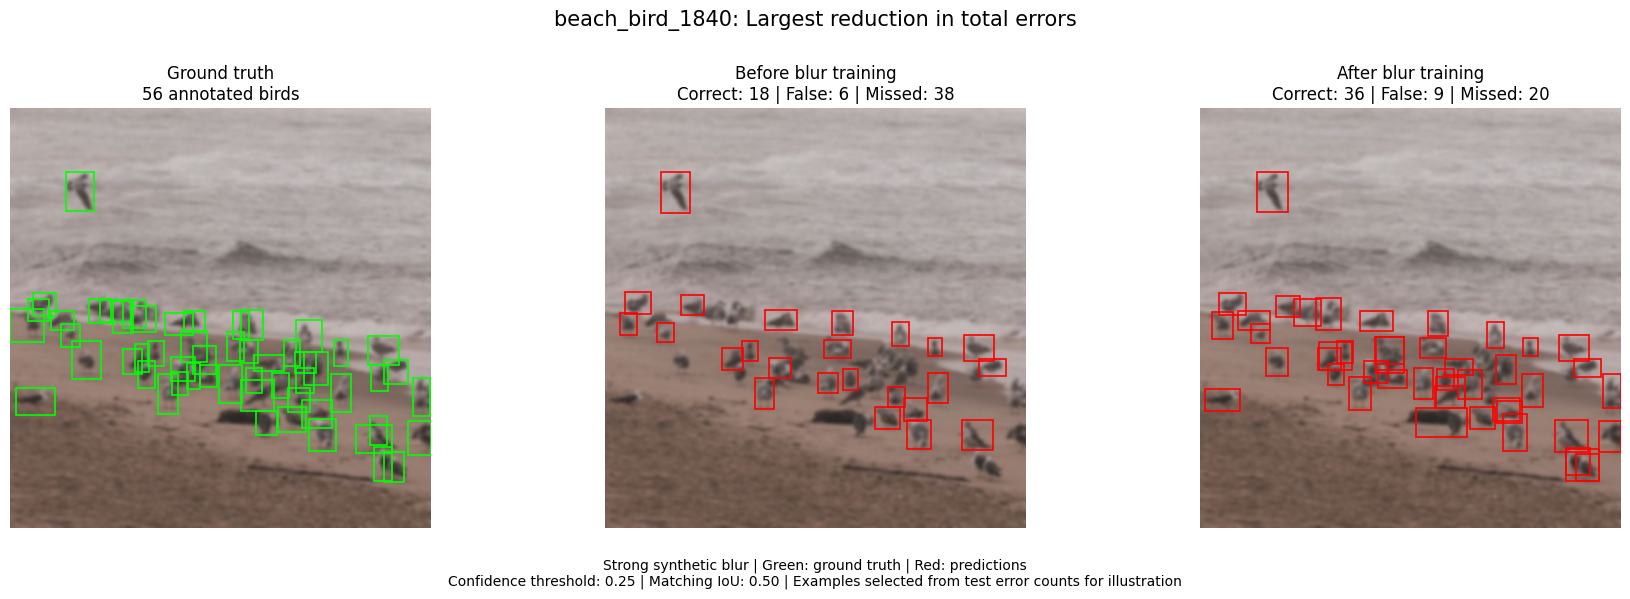

Saved: C:\Users\raksh\Desktop\CompVis\yolo_work\failure_analysis_v1\figures\beach_bird_1840_comparison.png
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


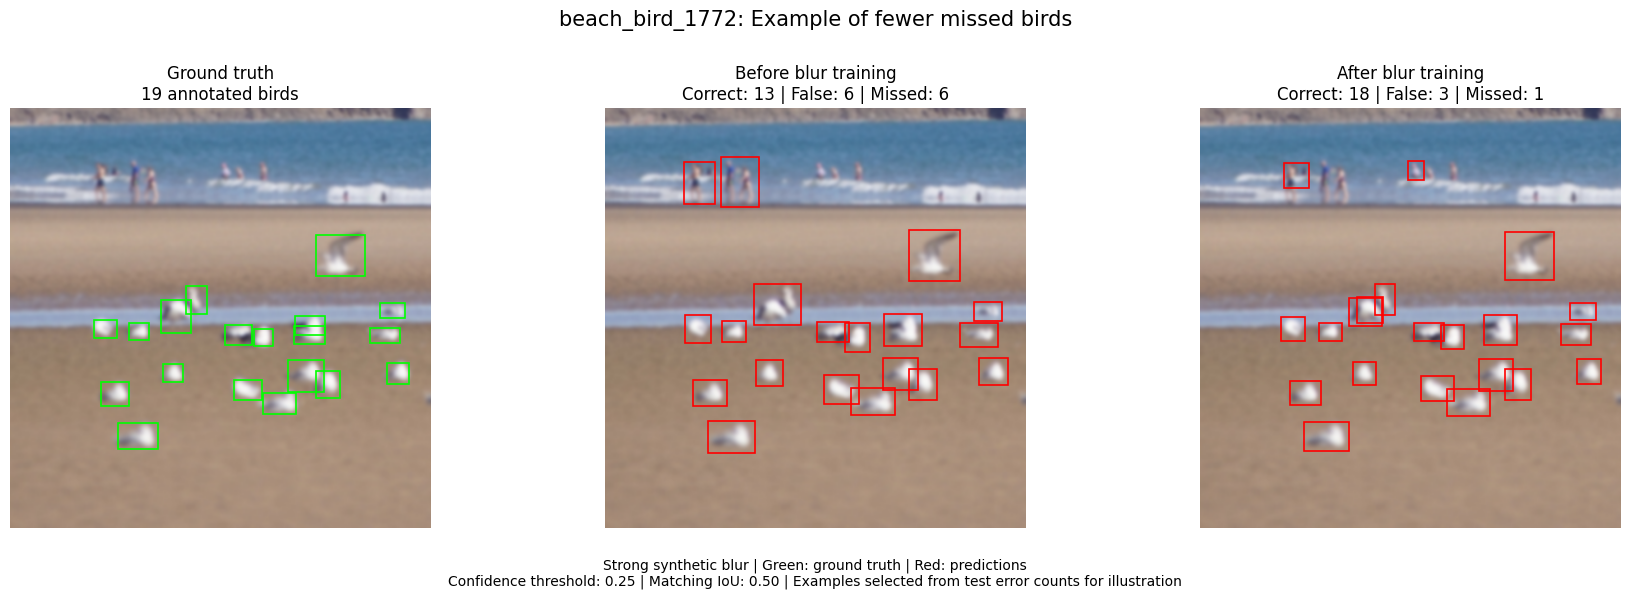

Saved: C:\Users\raksh\Desktop\CompVis\yolo_work\failure_analysis_v1\figures\beach_bird_1772_comparison.png
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


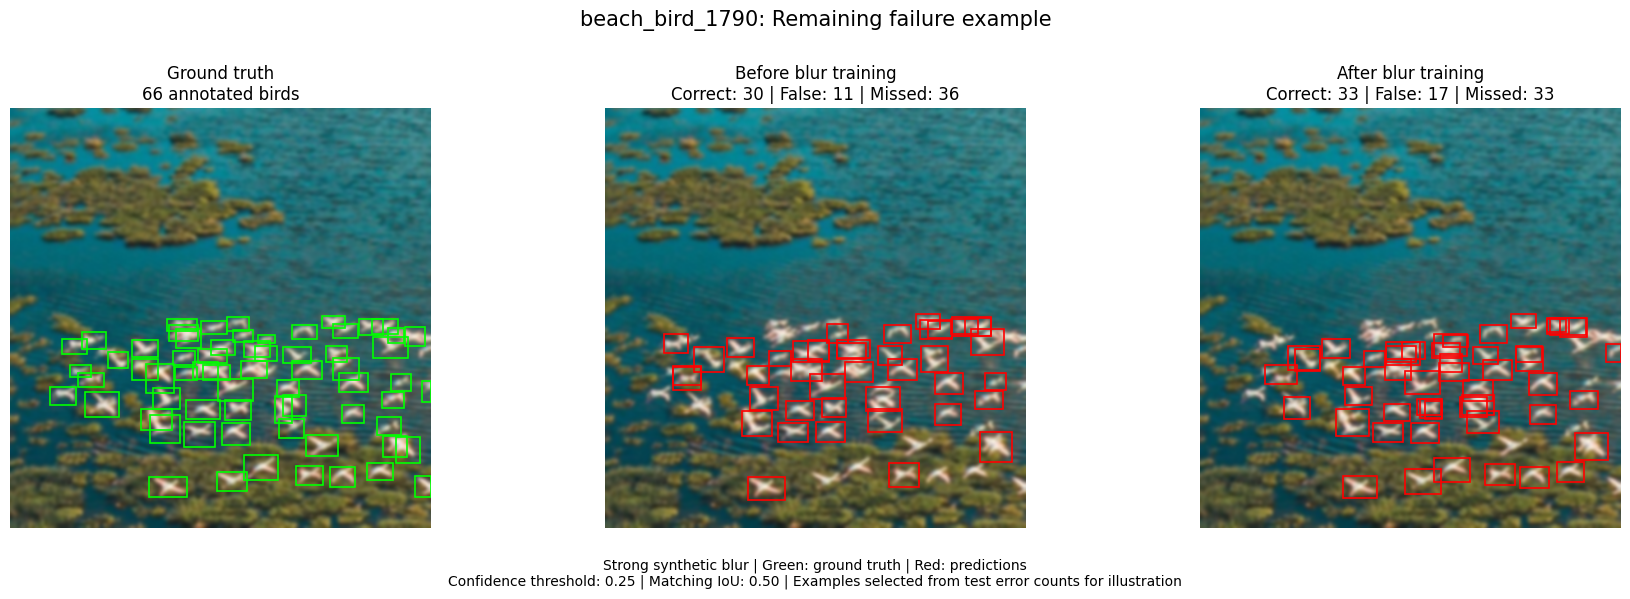

Saved: C:\Users\raksh\Desktop\CompVis\yolo_work\failure_analysis_v1\figures\beach_bird_1790_comparison.png

Done. Three comparison figures saved.


In [1]:
# Cell 27: Visual examples of improvement and remaining errors

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

YOLO_DIR = Path(r"C:\Users\raksh\Desktop\CompVis\yolo_work")
ANALYSIS_DIR = YOLO_DIR / "failure_analysis_v1"
FIGURE_DIR = ANALYSIS_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DATA_DIR = YOLO_DIR / "final_test_v1" / "datasets" / "blur_strong"

checkpoints = {
    "before_blur_training": (
        YOLO_DIR / "runs"
        / "flip_brightness_contrast_seed42_20261112_132822"
        / "weights" / "best.pt"
    ),
    "after_blur_training": (
        YOLO_DIR / "runs"
        / "flip_appearance_blur_seed42_20261114_232048"
        / "weights" / "best.pt"
    ),
}

examples = [
    ("beach_bird_1840.png", "Largest reduction in total errors"),
    ("beach_bird_1772.png", "Example of fewer missed birds"),
    ("beach_bird_1790.png", "Remaining failure example"),
]

errors = pd.read_csv(ANALYSIS_DIR / "per_image_errors.csv")

# Check required files before loading models.
required = list(checkpoints.values())
for filename, _ in examples:
    required.extend([
        DATA_DIR / "images" / "test" / filename,
        DATA_DIR / "labels" / "test" / f"{Path(filename).stem}.txt",
    ])

missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError("Missing files:\n" + "\n".join(missing))

models = {
    name: YOLO(str(checkpoint))
    for name, checkpoint in checkpoints.items()
}


def read_boxes(label_path, width, height):
    boxes = []

    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue

        _, xc, yc, bw, bh = map(float, line.split())
        boxes.append((
            (xc - bw / 2) * width,
            (yc - bh / 2) * height,
            bw * width,
            bh * height,
        ))

    return boxes


def draw_box(ax, x, y, width, height, colour):
    ax.add_patch(Rectangle(
        (x, y), width, height,
        fill=False, edgecolor=colour, linewidth=1.2,
    ))


for filename, description in examples:
    image_path = DATA_DIR / "images" / "test" / filename
    label_path = DATA_DIR / "labels" / "test" / f"{image_path.stem}.txt"

    with Image.open(image_path) as source:
        image = source.convert("RGB")

    gt_boxes = read_boxes(label_path, *image.size)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    for ax in axes:
        ax.imshow(image)
        ax.axis("off")

    # Ground truth panel
    for box in gt_boxes:
        draw_box(axes[0], *box, colour="lime")

    axes[0].set_title(
        f"Ground truth\n{len(gt_boxes)} annotated birds",
        fontsize=12,
    )

    # Prediction panels
    for ax, (model_name, model) in zip(axes[1:], models.items()):
        result = model.predict(
            source=str(image_path),
            imgsz=640,
            conf=0.25,
            iou=0.7,
            max_det=300,
            device="cpu",
            augment=False,
            half=False,
            rect=True,
            verbose=False,
            save=False,
        )[0]

        for x1, y1, x2, y2 in result.boxes.xyxy.cpu().numpy():
            draw_box(
                ax, x1, y1, x2 - x1, y2 - y1,
                colour="red",
            )

        record = errors.loc[
            (errors["model"] == model_name)
            & (errors["condition"] == "blur_strong")
            & (errors["image"] == filename)
        ]

        if len(record) != 1:
            raise ValueError(f"Expected one error record: {model_name}, {filename}")

        row = record.iloc[0]
        title = (
            "Before blur training"
            if model_name == "before_blur_training"
            else "After blur training"
        )

        ax.set_title(
            f"{title}\n"
            f"Correct: {int(row['true_positives'])} | "
            f"False: {int(row['false_positives'])} | "
            f"Missed: {int(row['false_negatives'])}",
            fontsize=12,
        )

    fig.suptitle(
        f"{image_path.stem}: {description}",
        fontsize=15,
    )

    fig.text(
        0.5, 0.02,
        "Strong synthetic blur | Green: ground truth | Red: predictions\n"
        "Confidence threshold: 0.25 | Matching IoU: 0.50 | "
        "Examples selected from test error counts for illustration",
        ha="center", fontsize=10,
    )

    fig.tight_layout(rect=[0, 0.09, 1, 0.93])

    output_path = FIGURE_DIR / f"{image_path.stem}_comparison.png"
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {output_path}")

print("\nDone. Three comparison figures saved.")

Using speed benchmark: C:\Users\raksh\Desktop\CompVis\yolo_work\inference_benchmark\20261115_153901\speed_summary.csv

FINAL TEST AND SPEED RESULTS


,Clean mAP@0.50 (%),Clean mAP@0.50:0.95 (%),Strong blur mAP@0.50 (%),Blur drop (percentage points),Mean latency (ms/image),Median latency (ms/image),95th percentile latency (ms/image),Serial images/second
YOLO11n training variant,,,,,,,,
Baseline,80.74,42.29,66.81,13.93,152.00,133.17,246.39,6.58
Horizontal flip,84.73,45.47,70.32,14.41,178.25,153.08,329.03,5.61
Flip + appearance,84.87,46.10,71.83,13.04,201.73,129.18,510.01,4.96
Flip + appearance + blur,84.31,45.70,77.80,6.51,149.49,132.67,228.05,6.69



CONFIDENCE = 0.25; MATCHING IoU = 0.50


,Model,Condition,Correct detections,False detections,Missed birds,Precision (%),Recall (%),F1 (%)
3,Flip + appearance,Clean,1227,358,291,77.41,80.83,79.08
1,Flip + appearance + blur,Clean,1220,384,298,76.06,80.37,78.16
2,Flip + appearance,Strong blur,949,223,569,80.97,62.52,70.56
0,Flip + appearance + blur,Strong blur,1064,276,454,79.40,70.09,74.46



TEST mAP@0.50 (%)


,Clean,Mild darkness,Strong darkness,Mild blur,Strong blur
YOLO11n training variant,,,,,
Baseline,80.74,80.25,77.94,78.93,66.81
Horizontal flip,84.73,84.20,77.76,83.01,70.32
Flip + appearance,84.87,84.65,79.92,83.58,71.83
Flip + appearance + blur,84.31,83.96,81.17,83.70,77.80


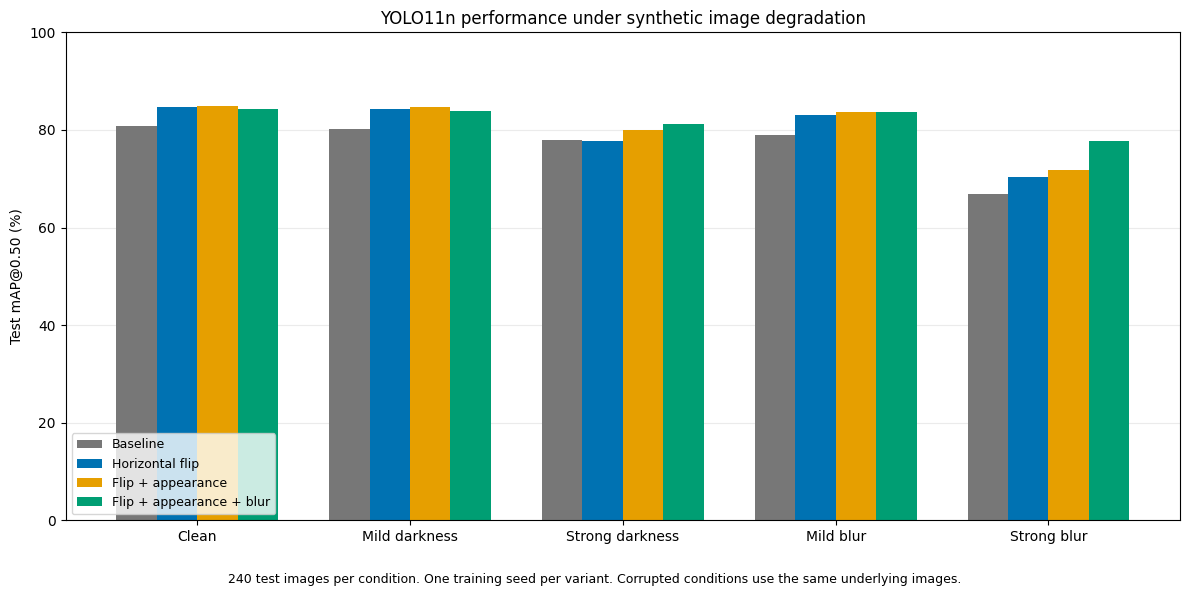


Saved tables and figures to: C:\Users\raksh\Desktop\CompVis\yolo_work\report_outputs
Speed measurements exclude image loading and model loading.
Runtime variation means these timings do not establish a faster architecture.


In [2]:
# Cell 28: Final report tables and robustness chart

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

YOLO_DIR = Path(r"C:\Users\raksh\Desktop\CompVis\yolo_work")
REPORT_DIR = YOLO_DIR / "report_outputs"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

test_path = YOLO_DIR / "final_test_v1" / "test_results.csv"
error_path = YOLO_DIR / "failure_analysis_v1" / "error_summary.csv"

# Find the most recently saved speed benchmark.
speed_files = list(
    (YOLO_DIR / "inference_benchmark").rglob("speed_summary.csv")
)
if not speed_files:
    raise FileNotFoundError("Could not find speed_summary.csv")

speed_path = max(speed_files, key=lambda path: path.stat().st_mtime)
print("Using speed benchmark:", speed_path)

test = pd.read_csv(test_path)
errors = pd.read_csv(error_path)
speed = pd.read_csv(speed_path)

model_order = [
    "baseline",
    "flips",
    "flips_brightness_contrast",
    "flips_appearance_blur",
]

model_labels = {
    "baseline": "Baseline",
    "flips": "Horizontal flip",
    "flips_brightness_contrast": "Flip + appearance",
    "flips_appearance_blur": "Flip + appearance + blur",
}

condition_order = [
    "clean", "dark_mild", "dark_strong", "blur_mild", "blur_strong"
]
condition_labels = [
    "Clean", "Mild darkness", "Strong darkness",
    "Mild blur", "Strong blur"
]

# Check that every model/condition pair appears exactly once.
expected = {(m, c) for m in model_order for c in condition_order}
observed = set(zip(test["model"], test["condition"]))

if test.duplicated(["model", "condition"]).any() or observed != expected:
    raise ValueError("Test results contain missing, extra or duplicate pairs.")

if speed["model"].duplicated().any():
    raise ValueError("Speed summary contains duplicate models.")

if not set(model_order).issubset(set(speed["model"])):
    raise ValueError("Speed summary is missing a model.")

# 1. Final accuracy and speed table
map50 = test.pivot(
    index="model", columns="condition", values="map50"
).loc[model_order, condition_order]

clean = (
    test.loc[test["condition"].eq("clean")]
    .set_index("model")
    .loc[model_order]
)
speed = speed.set_index("model").loc[model_order]

final_table = pd.DataFrame(index=model_order)
final_table["Clean mAP@0.50 (%)"] = clean["map50"] * 100
final_table["Clean mAP@0.50:0.95 (%)"] = clean["map50_95"] * 100
final_table["Strong blur mAP@0.50 (%)"] = map50["blur_strong"] * 100
final_table["Blur drop (percentage points)"] = (
    map50["clean"] - map50["blur_strong"]
) * 100
final_table["Mean latency (ms/image)"] = speed["mean_ms_per_image"]
final_table["Median latency (ms/image)"] = speed["median_ms_per_image"]
final_table["95th percentile latency (ms/image)"] = speed["p95_ms_per_image"]
final_table["Serial images/second"] = speed["serial_images_per_second"]

final_table.index = [model_labels[m] for m in final_table.index]
final_table.index.name = "YOLO11n training variant"

print("\nFINAL TEST AND SPEED RESULTS")
display(final_table.round(2))
final_table.to_csv(REPORT_DIR / "final_test_and_speed_table.csv")

# 2. Precision, recall and F1 at a fixed confidence threshold
fixed = errors.copy()

tp = fixed["true_positives"]
fp = fixed["false_positives"]
fn = fixed["false_negatives"]

fixed["Precision (%)"] = 100 * tp / (tp + fp).replace(0, np.nan)
fixed["Recall (%)"] = 100 * tp / (tp + fn).replace(0, np.nan)
fixed["F1 (%)"] = 100 * (2 * tp) / (2 * tp + fp + fn).replace(0, np.nan)

fixed["Model"] = fixed["model"].map({
    "before_blur_training": "Flip + appearance",
    "after_blur_training": "Flip + appearance + blur",
})
fixed["Condition"] = fixed["condition"].map({
    "clean": "Clean",
    "blur_strong": "Strong blur",
})

fixed_table = fixed[[
    "Model", "Condition",
    "true_positives", "false_positives", "false_negatives",
    "Precision (%)", "Recall (%)", "F1 (%)",
]].rename(columns={
    "true_positives": "Correct detections",
    "false_positives": "False detections",
    "false_negatives": "Missed birds",
}).sort_values(["Condition", "Model"])

print("\nCONFIDENCE = 0.25; MATCHING IoU = 0.50")
display(fixed_table.round(2))
fixed_table.to_csv(
    REPORT_DIR / "precision_recall_f1_conf025.csv", index=False
)

# 3. Full robustness table
robustness_table = map50 * 100
robustness_table.index = [
    model_labels[m] for m in robustness_table.index
]
robustness_table.index.name = "YOLO11n training variant"
robustness_table.columns = condition_labels

print("\nTEST mAP@0.50 (%)")
display(robustness_table.round(2))
robustness_table.to_csv(REPORT_DIR / "test_robustness_table.csv")

# 4. Grouped bar chart
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(condition_order))
bar_width = 0.19
colours = ["#777777", "#0072B2", "#E69F00", "#009E73"]

for i, model in enumerate(model_order):
    ax.bar(
        x + (i - 1.5) * bar_width,
        map50.loc[model].to_numpy() * 100,
        width=bar_width,
        label=model_labels[model],
        color=colours[i],
    )

ax.set_xticks(x)
ax.set_xticklabels(condition_labels)
ax.set_ylabel("Test mAP@0.50 (%)")
ax.set_ylim(0, 100)
ax.set_title("YOLO11n performance under synthetic image degradation")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc="lower left", fontsize=9)

fig.text(
    0.5, 0.02,
    "240 test images per condition. One training seed per variant. "
    "Corrupted conditions use the same underlying images.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.06, 1, 1])

fig.savefig(
    REPORT_DIR / "test_robustness_comparison.png",
    dpi=300, bbox_inches="tight",
)
fig.savefig(
    REPORT_DIR / "test_robustness_comparison.pdf",
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print("\nSaved tables and figures to:", REPORT_DIR)
print("Speed measurements exclude image loading and model loading.")
print("Runtime variation means these timings do not establish a faster architecture.")